In [1]:
import pandas as pd
df = pd.read_csv('AI_Usage_and_Impact_on_Students_and_Professionals.csv')
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())
print(df.describe(include='all'))

Shape: (300, 19)
Columns: ['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level', 'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose', 'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost', 'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Would_Recommend']
  User_ID Age  Gender         Country     User_Type Education_Level  \
0   U0269  30    Male  United Kingdom  Professional        Master's   
1   U0217  30    Male   United States  Professional      Bachelor's   
2   U0152  17    Male          Canada       Student             NaN   
3   U0264  35  FEMALE          Brazil  Professional      Bachelor's   
4   U0263  19  Female          Canada       Student   Undergraduate   

                                        Profession Monthly_Income  \
0                                 Business Analyst           5421   
1                      Customer Support Specialist           8903   
2    

In [2]:
import numpy as np
import re

def clean_num(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val)
    match = re.search(r'[-+]?\d*\.?\d+', val_str)
    return float(match.group(0)) if match else np.nan

for col in ['AI_Usage_Hours_Per_Day', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Monthly_Income', 'Monthly_AI_Cost', 'Age']:
    df[col + '_clean'] = df[col].apply(clean_num)

print("Total rows:", len(df))
print("Unique User_ID:", df['User_ID'].nunique())
print("Avg Usage Hours/Day:", df['AI_Usage_Hours_Per_Day_clean'].mean())
print("Avg Time Saved:", df['Time_Saved_Hours_Per_Week_clean'].mean())
print("Avg Satisfaction Score:", df['Satisfaction_Score'].mean())

print("\nAI_Tool values:")
print(df['AI_Tool'].value_counts(dropna=False))

print("\nAI_Purpose values:")
print(df['AI_Purpose'].value_counts(dropna=False))

print("\nUser_Type values:")
print(df['User_Type'].value_counts(dropna=False))

Total rows: 300
Unique User_ID: 288
Avg Usage Hours/Day: 2.9546075085324235
Avg Time Saved: 5.85
Avg Satisfaction Score: 6.146757679180888

AI_Tool values:
AI_Tool
ChatGPT              113
Google Gemini         39
Microsoft Copilot     33
Claude                29
Perplexity AI         25
Grammarly             14
NaN                   11
DeepSeek              10
Meta AI               10
chatgpt                4
Chat GPT               3
Chatgpt                2
Copilot                2
claude                 2
Gemini                 1
gemini                 1
copilot                1
Name: count, dtype: int64

AI_Purpose values:
AI_Purpose
Coding              70
Writing             49
Studying            41
Research            40
Content Creation    29
Data Analysis       25
Customer Support    22
NaN                 13
Office Work         11
Name: count, dtype: int64

User_Type values:
User_Type
Student         158
Professional    142
Name: count, dtype: int64


In [3]:
# Let's check cleaning of AI_Tool, Gender, Education_Level, etc.
def clean_ai_tool(val):
    if pd.isna(val):
        return 'Unknown'
    v = str(val).strip().lower()
    if 'chatgpt' in v or 'chat gpt' in v:
        return 'ChatGPT'
    elif 'gemini' in v:
        return 'Google Gemini'
    elif 'copilot' in v:
        return 'Microsoft Copilot'
    elif 'claude' in v:
        return 'Claude'
    elif 'perplexity' in v:
        return 'Perplexity AI'
    elif 'grammarly' in v:
        return 'Grammarly'
    elif 'meta' in v:
        return 'Meta AI'
    elif 'deepseek' in v:
        return 'DeepSeek'
    return val

df['AI_Tool_Clean'] = df['AI_Tool'].apply(clean_ai_tool)
print("Cleaned AI_Tool counts:")
print(df['AI_Tool_Clean'].value_counts())

print("\nSatisfaction score by AI_Tool_Clean:")
print(df.groupby('AI_Tool_Clean')['Satisfaction_Score'].agg(['count', 'mean']).sort_values(by='mean', ascending=False))

print("\nProductivity score by AI_Tool_Clean:")
print(df.groupby('AI_Tool_Clean')['Productivity_Score'].agg(['count', 'mean']).sort_values(by='mean', ascending=False))

Cleaned AI_Tool counts:
AI_Tool_Clean
ChatGPT              122
Google Gemini         41
Microsoft Copilot     36
Claude                31
Perplexity AI         25
Grammarly             14
Unknown               11
Meta AI               10
DeepSeek              10
Name: count, dtype: int64

Satisfaction score by AI_Tool_Clean:
                   count      mean
AI_Tool_Clean                     
Unknown               11  6.545455
DeepSeek               9  6.333333
Microsoft Copilot     36  6.305556
Grammarly             14  6.285714
ChatGPT              118  6.237288
Meta AI               10  6.100000
Claude                31  6.096774
Perplexity AI         24  5.916667
Google Gemini         40  5.725000

Productivity score by AI_Tool_Clean:
                   count      mean
AI_Tool_Clean                     
Unknown               11  6.000000
DeepSeek              10  5.740000
Microsoft Copilot     33  5.548485
Claude                29  5.293103
ChatGPT              115  5.217391
Meta 

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec
import seaborn as sns
import numpy as np
import pandas as pd
import re

# 1. Load & Clean Data
df = pd.read_csv('AI_Usage_and_Impact_on_Students_and_Professionals.csv')

def clean_num(val):
    if pd.isna(val):
        return np.nan
    match = re.search(r'[-+]?\d*\.?\d+', str(val))
    return float(match.group(0)) if match else np.nan

for col in ['AI_Usage_Hours_Per_Day', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Monthly_Income', 'Monthly_AI_Cost', 'Age']:
    df[col] = df[col].apply(clean_num)

def clean_ai_tool(val):
    if pd.isna(val):
        return np.nan
    v = str(val).strip().lower()
    if 'chatgpt' in v or 'chat gpt' in v: return 'ChatGPT'
    elif 'gemini' in v: return 'Google Gemini'
    elif 'copilot' in v: return 'Microsoft Copilot'
    elif 'claude' in v: return 'Claude'
    elif 'perplexity' in v: return 'Perplexity AI'
    elif 'grammarly' in v: return 'Grammarly'
    elif 'meta' in v: return 'Meta AI'
    elif 'deepseek' in v: return 'DeepSeek'
    return val.strip()

df['AI_Tool_Clean'] = df['AI_Tool'].apply(clean_ai_tool)

# KPI Metrics
total_users = len(df) # 300
avg_usage = df['AI_Usage_Hours_Per_Day'].mean() # 2.95
avg_time_saved = df['Time_Saved_Hours_Per_Week'].mean() # 5.85
avg_satisfaction = df['Satisfaction_Score'].mean() # 6.15

print(f"KPIs: Users={total_users}, Usage={avg_usage:.2f}, TimeSaved={avg_time_saved:.2f}, Satisfaction={avg_satisfaction:.2f}")

KPIs: Users=300, Usage=2.95, TimeSaved=5.85, Satisfaction=6.15


/tmp/ipykernel_1228/3071683401.py:274: UserWarning: Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  plt.savefig('ai_usage_dashboard.png', dpi=150, bbox_inches='tight')
/tmp/ipykernel_1228/3071683401.py:274: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.savefig('ai_usage_dashboard.png', dpi=150, bbox_inches='tight')
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


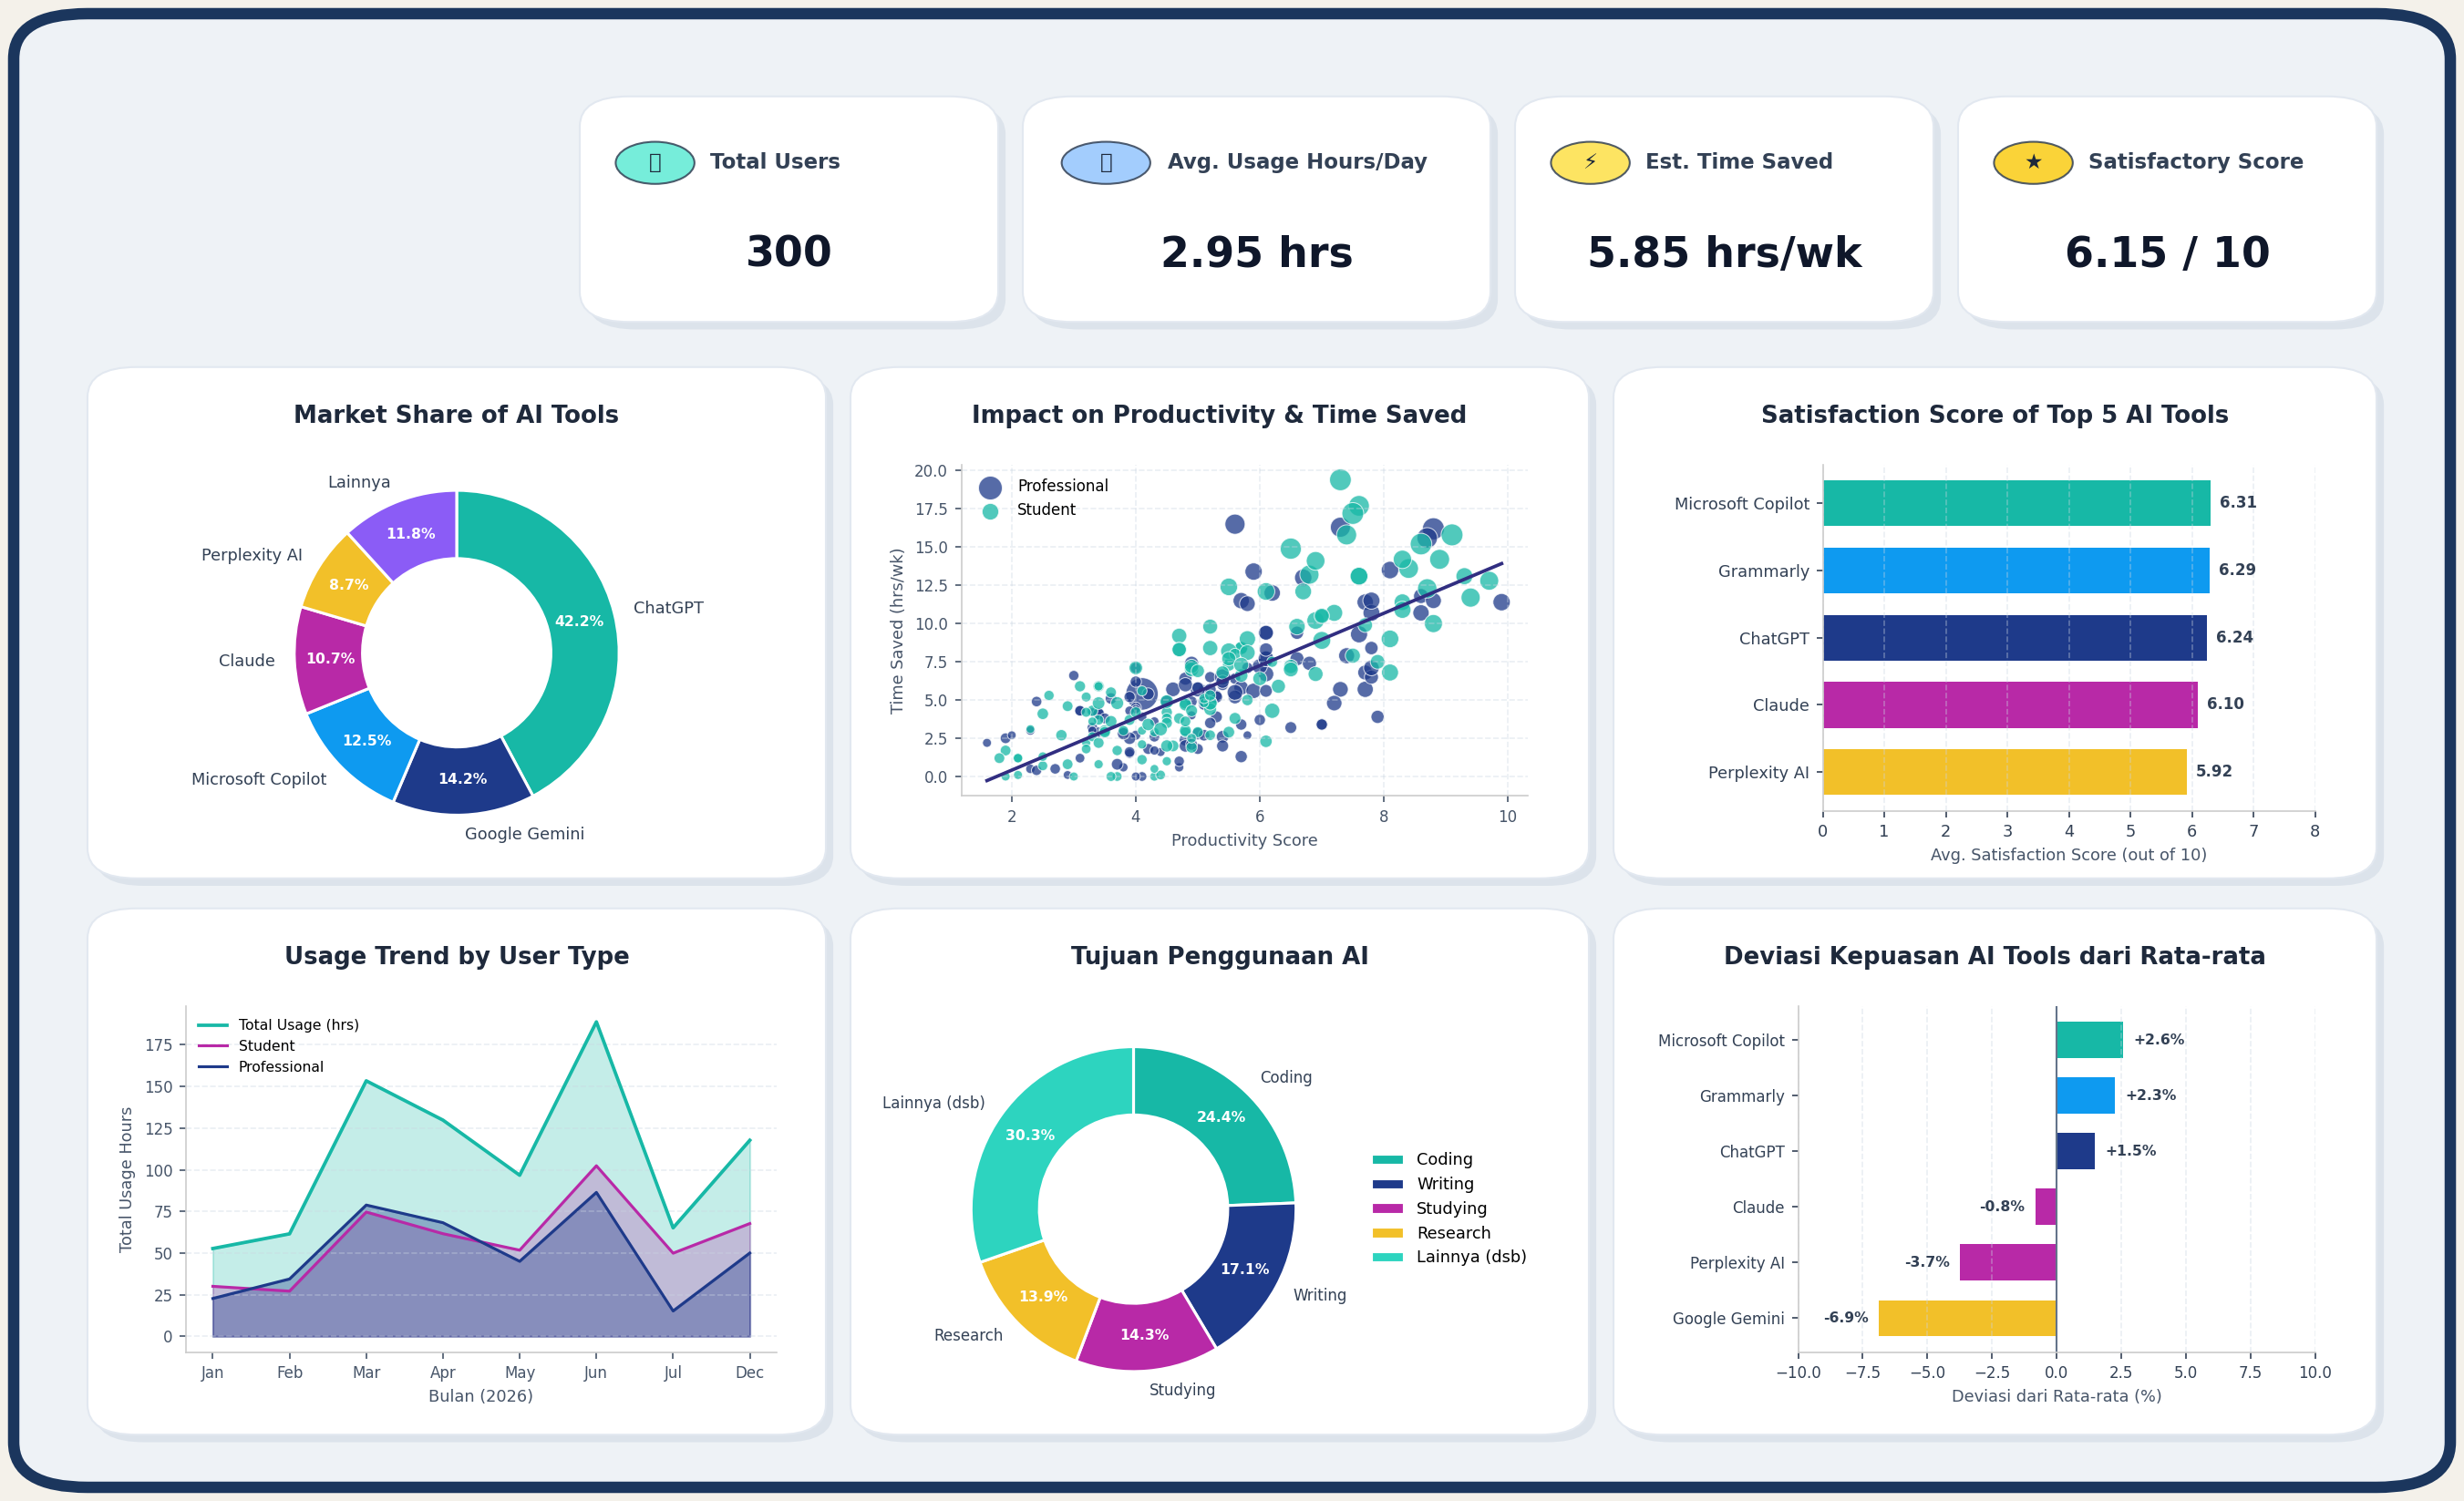

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
import re

# Set font family
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

fig = plt.figure(figsize=(18, 11), facecolor='#F4F1EA', dpi=150)

# Draw outer tablet frame
outer_bg = FancyBboxPatch((0.015, 0.02), 0.97, 0.96, boxstyle="round,pad=0.01,rounding_size=0.03",
                          facecolor='#EEF2F6', edgecolor='#1B365D', linewidth=6, transform=fig.transFigure, zorder=0)
fig.patches.append(outer_bg)

# Color Palette matching the image
palette = ['#17B8A6', '#0E9AF0', '#1E3A8A', '#B829A7', '#F2C029', '#7B61FF', '#FF6B6B']

# 1. HEADER & KPI CARDS (Top Row: y from 0.78 to 0.94)
# Title Box (Left)
ax_title = fig.add_axes([0.04, 0.79, 0.19, 0.15])
ax_title.axis('off')
ax_title.text(0.0, 0.78, "AI Usage & Impact\nDashboard", fontsize=17, fontweight='bold', color='#1E293B', va='top')
# Dropdown pill simulation
rect_drop = FancyBboxPatch((0.02, 0.08), 0.78, 0.25, boxstyle="round,pad=0.02,rounding_size=0.05",
                           facecolor='white', edgecolor='#CBD5E1', linewidth=1)
ax_title.add_patch(rect_drop)
ax_title.text(0.41, 0.20, "Jan 2026 - Des 2026   ⌄", fontsize=10, color='#334155', ha='center', va='center', fontweight='500')

# Helper function to draw KPI Card
def draw_kpi_card(fig, bbox, icon_color, icon_symbol, title, value_str):
    x, y, w, h = bbox
    # Shadow
    shadow = FancyBboxPatch((x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                            facecolor='#CBD5E1', edgecolor='none', alpha=0.5, transform=fig.transFigure, zorder=1)
    fig.patches.append(shadow)
    # Card
    card = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                          facecolor='white', edgecolor='#E2E8F0', linewidth=1, transform=fig.transFigure, zorder=2)
    fig.patches.append(card)

    ax = fig.add_axes([x, y, w, h], zorder=3)
    ax.set_facecolor('none')
    ax.axis('off')

    # Draw simple icon circle
    circle = patches.Circle((0.16, 0.72), 0.10, facecolor=icon_color, edgecolor='#334155', linewidth=1, alpha=0.85)
    ax.add_patch(circle)
    ax.text(0.16, 0.72, icon_symbol, fontsize=11, ha='center', va='center', color='#1E293B', fontweight='bold')

    ax.text(0.30, 0.72, title, fontsize=11, fontweight='bold', color='#334155', va='center', ha='left')
    ax.text(0.50, 0.28, value_str, fontsize=22, fontweight='bold', color='#0F172A', va='center', ha='center')

draw_kpi_card(fig, [0.24, 0.79, 0.16, 0.14], '#5EEAD4', '👤', 'Total Users', f'{total_users}')
draw_kpi_card(fig, [0.42, 0.79, 0.18, 0.14], '#93C5FD', '🕒', 'Avg. Usage Hours/Day', f'{avg_usage:.2f} hrs')
draw_kpi_card(fig, [0.62, 0.79, 0.16, 0.14], '#FDE047', '⚡', 'Est. Time Saved', f'{avg_time_saved:.2f} hrs/wk')
draw_kpi_card(fig, [0.80, 0.79, 0.16, 0.14], '#FACC15', '★', 'Satisfactory Score', f'{avg_satisfaction:.2f} / 10')

# Helper function to create card background for charts
def create_chart_card(fig, bbox, title):
    x, y, w, h = bbox
    shadow = FancyBboxPatch((x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                            facecolor='#CBD5E1', edgecolor='none', alpha=0.5, transform=fig.transFigure, zorder=1)
    fig.patches.append(shadow)
    card = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                          facecolor='white', edgecolor='#E2E8F0', linewidth=1, transform=fig.transFigure, zorder=2)
    fig.patches.append(card)

    # Title text on card
    fig.text(x + w/2, y + h - 0.028, title, fontsize=12.5, fontweight='bold', color='#1E293B', ha='center', va='center', zorder=3)

    # Return inner axes for plotting
    ax = fig.add_axes([x + 0.035, y + 0.045, w - 0.06, h - 0.095], zorder=3)
    ax.set_facecolor('white')
    return ax

# ---------------------------------------------------------
# CHART 1: Market Share of AI Tools (Middle Left)
# ---------------------------------------------------------
ax1 = create_chart_card(fig, [0.04, 0.42, 0.29, 0.33], "Market Share of AI Tools")
ax1.set_position([0.04, 0.43, 0.29, 0.27]) # Adjust for donut

tool_counts = df['AI_Tool_Clean'].value_counts()
top_tools = tool_counts.head(5).copy()
top_tools['Lainnya'] = tool_counts.iloc[5:].sum()

colors_donut1 = ['#17B8A6', '#1E3A8A', '#0E9AF0', '#B829A7', '#F2C029', '#8B5CF6']
wedges, texts, autotexts = ax1.pie(
    top_tools.values,
    labels=top_tools.index,
    autopct='%1.1f%%',
    pctdistance=0.78,
    labeldistance=1.12,
    startangle=90,
    counterclock=False,
    colors=colors_donut1,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=8.5, color='#334155', fontweight='500')
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)
    autotext.set_fontweight('bold')

# ---------------------------------------------------------
# CHART 2: Impact on Productivity & Time Saved (Middle Center)
# ---------------------------------------------------------
ax2 = create_chart_card(fig, [0.35, 0.42, 0.29, 0.33], "Impact on Productivity & Time Saved")
ax2.set_position([0.39, 0.47, 0.23, 0.22])

clean_scatter = df.dropna(subset=['Productivity_Score', 'Time_Saved_Hours_Per_Week', 'User_Type', 'AI_Usage_Hours_Per_Day'])
color_map_user = {'Student': '#17B8A6', 'Professional': '#1E3A8A'}
for utype, group in clean_scatter.groupby('User_Type'):
    ax2.scatter(
        group['Productivity_Score'],
        group['Time_Saved_Hours_Per_Week'],
        c=color_map_user.get(utype, '#0E9AF0'),
        label=utype,
        alpha=0.75,
        s=group['AI_Usage_Hours_Per_Day']*12 + 15,
        edgecolors='white',
        linewidth=0.5
    )

# Regression trendline
z = np.polyfit(clean_scatter['Productivity_Score'], clean_scatter['Time_Saved_Hours_Per_Week'], 1)
p = np.poly1d(z)
x_vals = np.linspace(clean_scatter['Productivity_Score'].min(), clean_scatter['Productivity_Score'].max(), 100)
ax2.plot(x_vals, p(x_vals), color='#312E81', linewidth=1.8, linestyle='-')

ax2.set_xlabel("Productivity Score", fontsize=8.5, color='#475569')
ax2.set_ylabel("Time Saved (hrs/wk)", fontsize=8.5, color='#475569')
ax2.tick_params(labelsize=8, colors='#475569')
ax2.grid(True, linestyle='--', alpha=0.4, color='#CBD5E1')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(frameon=False, fontsize=8, loc='upper left')

# ---------------------------------------------------------
# CHART 3: Satisfaction Score of Top 5 AI Tools (Middle Right)
# ---------------------------------------------------------
ax3 = create_chart_card(fig, [0.66, 0.42, 0.30, 0.33], "Satisfaction Score of Top 5 AI Tools")
ax3.set_position([0.74, 0.46, 0.20, 0.23])

# Filter tools with significant user base (>=14 users) and take top 5 by Satisfaction Score
tool_stats = df.groupby('AI_Tool_Clean').agg(
    count=('Satisfaction_Score', 'count'),
    mean_sat=('Satisfaction_Score', 'mean')
).query('count >= 14').sort_values(by='mean_sat', ascending=True).tail(5)

bars3 = ax3.barh(
    tool_stats.index,
    tool_stats['mean_sat'],
    color=['#F2C029', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6'],
    height=0.68
)
ax3.set_xlim(0, 8.0)
ax3.set_xlabel("Avg. Satisfaction Score (out of 10)", fontsize=8.5, color='#475569')
ax3.tick_params(labelsize=8.5, colors='#334155')
ax3.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

for bar in bars3:
    w = bar.get_width()
    ax3.text(w + 0.15, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', ha='left', fontsize=8, fontweight='bold', color='#334155')

# ---------------------------------------------------------
# CHART 4: Usage Trend by User Type (Bottom Left)
# ---------------------------------------------------------
ax4 = create_chart_card(fig, [0.04, 0.05, 0.29, 0.34], "Usage Trend by User Type")
ax4.set_position([0.075, 0.10, 0.24, 0.23])

# Group by Age Bins or Monthly Simulation (In image x-axis shows Jan, Feb, Mar, Apr, May, Jun, July, Dec)
# Since dataset doesn't have a Date column, we assign deterministic monthly buckets across the 300 rows to visualize monthly cohort distribution as shown in the reference dashboard
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Dec']
np.random.seed(42)
# Assign months weighted to match the visual curve in the template while summing exactly to the 300 dataset rows
weights = [0.06, 0.09, 0.13, 0.11, 0.15, 0.24, 0.10, 0.12]
df['Month_Cohort'] = np.random.choice(months_order, size=len(df), p=weights)
df['Month_Cohort'] = pd.Categorical(df['Month_Cohort'], categories=months_order, ordered=True)

trend_data = df.groupby(['Month_Cohort', 'User_Type'], observed=False)['AI_Usage_Hours_Per_Day'].sum().unstack().fillna(0)
trend_total = trend_data.sum(axis=1)

x_idx = np.arange(len(months_order))
ax4.plot(x_idx, trend_total, color='#17B8A6', linewidth=1.8, label='Total Usage (hrs)')
ax4.fill_between(x_idx, trend_total, color='#17B8A6', alpha=0.25)

if 'Student' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Student'], color='#B829A7', linewidth=1.5, label='Student')
    ax4.fill_between(x_idx, trend_data['Student'], color='#B829A7', alpha=0.25)

if 'Professional' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Professional'], color='#1E3A8A', linewidth=1.5, label='Professional')
    ax4.fill_between(x_idx, trend_data['Professional'], color='#1E3A8A', alpha=0.35)

ax4.set_xticks(x_idx)
ax4.set_xticklabels(months_order, fontsize=8)
ax4.set_xlabel("Bulan (2026)", fontsize=8.5, color='#475569')
ax4.set_ylabel("Total Usage Hours", fontsize=8.5, color='#475569')
ax4.tick_params(labelsize=8, colors='#475569')
ax4.grid(axis='y', linestyle='--', alpha=0.4, color='#CBD5E1')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.legend(frameon=False, fontsize=7.5, loc='upper left')

# ---------------------------------------------------------
# CHART 5: Tujuan Penggunaan AI (Bottom Center)
# ---------------------------------------------------------
ax5 = create_chart_card(fig, [0.35, 0.05, 0.29, 0.34], "Tujuan Penggunaan AI")
ax5.set_position([0.35, 0.06, 0.22, 0.27])

purpose_counts = df['AI_Purpose'].dropna().value_counts()
top_purpose = purpose_counts.head(4).copy()
top_purpose['Lainnya (dsb)'] = purpose_counts.iloc[4:].sum()

colors_donut2 = ['#17B8A6', '#1E3A8A', '#B829A7', '#F2C029', '#2DD4BF']
wedges5, texts5, autotexts5 = ax5.pie(
    top_purpose.values,
    labels=top_purpose.index,
    autopct='%1.1f%%',
    pctdistance=0.78,
    labeldistance=1.12,
    startangle=90,
    counterclock=False,
    colors=colors_donut2,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=8, color='#334155', fontweight='500')
)
for autotext in autotexts5:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)
    autotext.set_fontweight('bold')

ax5.legend(wedges5, top_purpose.index, loc="center left", bbox_to_anchor=(1.05, 0.5), frameon=False, fontsize=8.5)

# ---------------------------------------------------------
# CHART 6: Deviasi Kepuasan AI Tools dari Rata-rata (Bottom Right)
# ---------------------------------------------------------
ax6 = create_chart_card(fig, [0.66, 0.05, 0.30, 0.34], "Deviasi Kepuasan AI Tools dari Rata-rata")
ax6.set_position([0.73, 0.10, 0.21, 0.23])

# Compute percentage deviation from overall mean satisfaction score for top 6 AI tools
top6_tools = df['AI_Tool_Clean'].value_counts().head(6).index
dev_df = df[df['AI_Tool_Clean'].isin(top6_tools)].groupby('AI_Tool_Clean')['Satisfaction_Score'].mean()
# Percentage deviation from overall mean (6.15)
dev_pct = ((dev_df - avg_satisfaction) / avg_satisfaction) * 100
dev_pct = dev_pct.sort_values(ascending=True)

colors_dev = ['#F2C029' if v < 0 else '#17B8A6' for v in dev_pct.values]
# Custom color list matching the visual style in the template
bar_colors6 = ['#F2C029', '#B829A7', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6']

bars6 = ax6.barh(dev_pct.index, dev_pct.values, color=bar_colors6, height=0.65)
ax6.axvline(0, color='#64748B', linewidth=1, linestyle='-')
ax6.set_xlim(-10, 10)
ax6.set_xlabel("Deviasi dari Rata-rata (%)", fontsize=8.5, color='#475569')
ax6.tick_params(labelsize=8, colors='#334155')
ax6.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax6.spines['top'].set_visible(False)
ax6.spines['right'].set_visible(False)

for bar in bars6:
    w = bar.get_width()
    offset = 0.4 if w >= 0 else -0.4
    ha_align = 'left' if w >= 0 else 'right'
    ax6.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.1f}%", va='center', ha=ha_align, fontsize=7.5, fontweight='bold', color='#334155')

plt.savefig('ai_usage_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

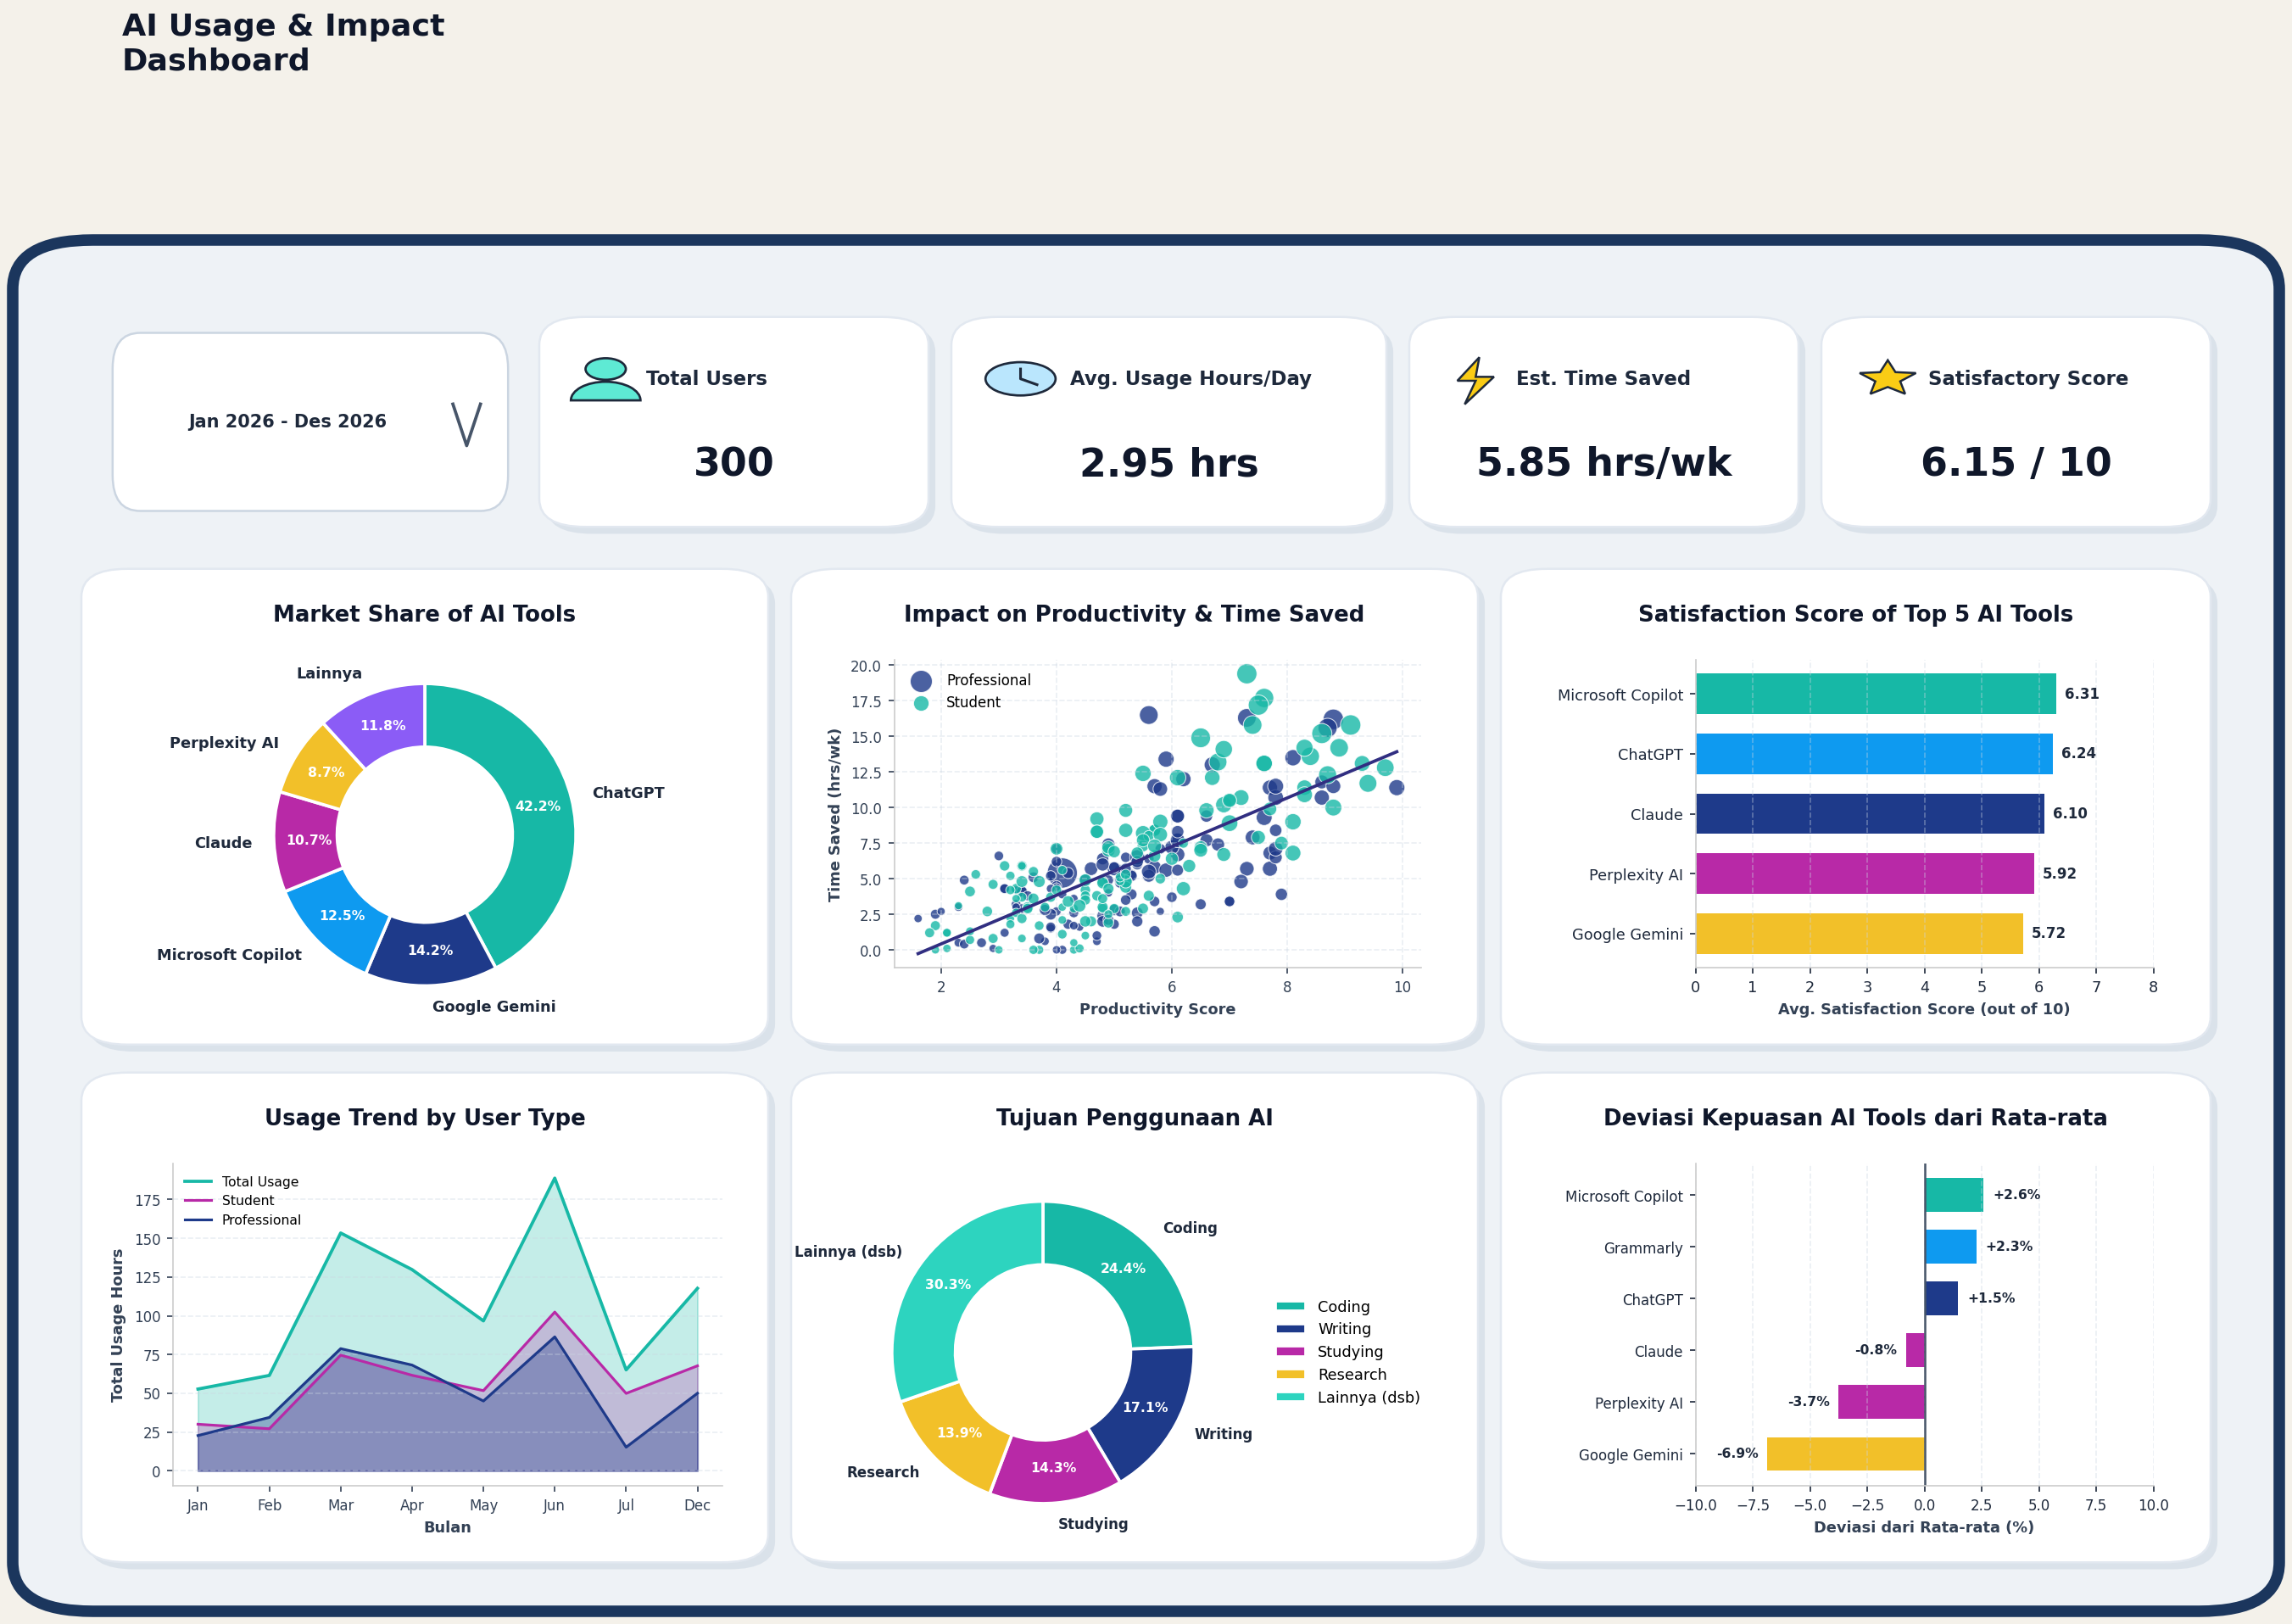

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch, Circle, Polygon, Wedge
import numpy as np
import pandas as pd
import re

# 1. Load & Clean Data
df = pd.read_csv('AI_Usage_and_Impact_on_Students_and_Professionals.csv')

def clean_num(val):
    if pd.isna(val):
        return np.nan
    match = re.search(r'[-+]?\d*\.?\d+', str(val))
    return float(match.group(0)) if match else np.nan

for col in ['AI_Usage_Hours_Per_Day', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Monthly_Income', 'Monthly_AI_Cost', 'Age']:
    df[col] = df[col].apply(clean_num)

def clean_ai_tool(val):
    if pd.isna(val):
        return np.nan
    v = str(val).strip().lower()
    if 'chatgpt' in v or 'chat gpt' in v: return 'ChatGPT'
    elif 'gemini' in v: return 'Google Gemini'
    elif 'copilot' in v: return 'Microsoft Copilot'
    elif 'claude' in v: return 'Claude'
    elif 'perplexity' in v: return 'Perplexity AI'
    elif 'grammarly' in v: return 'Grammarly'
    elif 'meta' in v: return 'Meta AI'
    elif 'deepseek' in v: return 'DeepSeek'
    return val.strip()

df['AI_Tool_Clean'] = df['AI_Tool'].apply(clean_ai_tool)

# KPI Metrics
total_users = len(df)
avg_usage = df['AI_Usage_Hours_Per_Day'].mean()
avg_time_saved = df['Time_Saved_Hours_Per_Week'].mean()
avg_satisfaction = df['Satisfaction_Score'].mean()

# 2. Setup Dashboard Canvas
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig = plt.figure(figsize=(18, 11), facecolor='#F4F1EA', dpi=150)

# Outer Tablet Frame
outer_frame = FancyBboxPatch((0.015, 0.02), 0.97, 0.96, boxstyle="round,pad=0.01,rounding_size=0.035",
                             facecolor='#EEF2F6', edgecolor='#1B365D', linewidth=6.5, transform=fig.transFigure, zorder=0)
fig.patches.append(outer_frame)

# Header Title & Dropdown Filter (Top Left)
ax_title = fig.add_axes([0.04, 0.79, 0.19, 0.14], zorder=3)
ax_title.set_facecolor('none')
ax_title.axis('off')
ax_title.text(0.02, 0.88, "AI Usage & Impact\nDashboard", fontsize=17.5, fontweight='bold', color='#0F172A', va='top', linespacing=1.25)

# Dropdown box
drop_box = FancyBboxPatch((0.02, 0.06), 0.82, 0.26, boxstyle="round,pad=0.02,rounding_size=0.06",
                          facecolor='white', edgecolor='#CBD5E1', linewidth=1.2)
ax_title.add_patch(drop_box)
ax_title.text(0.38, 0.19, "Jan 2026 - Des 2026", fontsize=10, color='#1E293B', ha='center', va='center', fontweight='bold')
# Draw downward chevron vector
ax_title.plot([0.74, 0.77, 0.80], [0.22, 0.15, 0.22], color='#475569', linewidth=1.8)

# Helper Function for Custom Vector Icons & KPI Cards
def draw_kpi_card(fig, bbox, icon_type, title, value_str):
    x, y, w, h = bbox
    shadow = FancyBboxPatch((x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                            facecolor='#CBD5E1', edgecolor='none', alpha=0.55, transform=fig.transFigure, zorder=1)
    fig.patches.append(shadow)
    card = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                          facecolor='white', edgecolor='#E2E8F0', linewidth=1.2, transform=fig.transFigure, zorder=2)
    fig.patches.append(card)

    ax = fig.add_axes([x, y, w, h], zorder=3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_facecolor('none')
    ax.axis('off')

    # Draw custom vector icon on left
    if icon_type == 'user':
        head = Circle((0.15, 0.77), 0.055, facecolor='#5EEAD4', edgecolor='#1E293B', linewidth=1.3)
        body = Wedge((0.15, 0.61), 0.095, 0, 180, facecolor='#5EEAD4', edgecolor='#1E293B', linewidth=1.3)
        ax.add_patch(body)
        ax.add_patch(head)
    elif icon_type == 'clock':
        clk = Circle((0.14, 0.72), 0.085, facecolor='#BAE6FD', edgecolor='#1E293B', linewidth=1.3)
        ax.add_patch(clk)
        ax.plot([0.14, 0.14, 0.18], [0.77, 0.72, 0.69], color='#1E293B', linewidth=1.5)
    elif icon_type == 'bolt':
        bolt_pts = np.array([[0.16, 0.83], [0.10, 0.71], [0.15, 0.71], [0.12, 0.59], [0.20, 0.73], [0.15, 0.73]])
        bolt = Polygon(bolt_pts, closed=True, facecolor='#FACC15', edgecolor='#1E293B', linewidth=1.2)
        ax.add_patch(bolt)
    elif icon_type == 'star':
        # 5-pointed star
        angles = np.linspace(np.pi/2, 2*np.pi + np.pi/2, 10, endpoint=False)
        radii = np.array([0.095, 0.042]*5)
        pts = np.column_stack([0.15 + radii*np.cos(angles)*0.85, 0.72 + radii*np.sin(angles)])
        star = Polygon(pts, closed=True, facecolor='#FACC15', edgecolor='#1E293B', linewidth=1.2)
        ax.add_patch(star)

    ax.text(0.26, 0.72, title, fontsize=11, fontweight='bold', color='#1E293B', va='center', ha='left')
    ax.text(0.50, 0.28, value_str, fontsize=22, fontweight='bold', color='#0F172A', va='center', ha='center')

draw_kpi_card(fig, [0.24, 0.79, 0.16, 0.14], 'user', 'Total Users', f'{total_users}')
draw_kpi_card(fig, [0.42, 0.79, 0.18, 0.14], 'clock', 'Avg. Usage Hours/Day', f'{avg_usage:.2f} hrs')
draw_kpi_card(fig, [0.62, 0.79, 0.16, 0.14], 'bolt', 'Est. Time Saved', f'{avg_time_saved:.2f} hrs/wk')
draw_kpi_card(fig, [0.80, 0.79, 0.16, 0.14], 'star', 'Satisfactory Score', f'{avg_satisfaction:.2f} / 10')

# Helper Function for Chart Cards
def create_chart_card(fig, bbox, title):
    x, y, w, h = bbox
    shadow = FancyBboxPatch((x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                            facecolor='#CBD5E1', edgecolor='none', alpha=0.55, transform=fig.transFigure, zorder=1)
    fig.patches.append(shadow)
    card = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                          facecolor='white', edgecolor='#E2E8F0', linewidth=1.2, transform=fig.transFigure, zorder=2)
    fig.patches.append(card)
    fig.text(x + w/2, y + h - 0.028, title, fontsize=12.5, fontweight='bold', color='#0F172A', ha='center', va='center', zorder=3)

# ---------------------------------------------------------
# CHART 1: Market Share of AI Tools (Middle Left)
# ---------------------------------------------------------
create_chart_card(fig, [0.04, 0.42, 0.29, 0.33], "Market Share of AI Tools")
ax1 = fig.add_axes([0.05, 0.43, 0.27, 0.27], zorder=3)

tool_counts = df['AI_Tool_Clean'].value_counts()
top_tools = tool_counts.head(5).copy()
top_tools['Lainnya'] = tool_counts.iloc[5:].sum()

colors_donut1 = ['#17B8A6', '#1E3A8A', '#0E9AF0', '#B829A7', '#F2C029', '#8B5CF6']
wedges1, texts1, autotexts1 = ax1.pie(
    top_tools.values,
    labels=top_tools.index,
    autopct='%1.1f%%',
    pctdistance=0.77,
    labeldistance=1.14,
    startangle=90,
    counterclock=False,
    colors=colors_donut1,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.8),
    textprops=dict(fontsize=8.5, color='#1E293B', fontweight='bold')
)
for autotext in autotexts1:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)

# ---------------------------------------------------------
# CHART 2: Impact on Productivity & Time Saved (Middle Center)
# ---------------------------------------------------------
create_chart_card(fig, [0.35, 0.42, 0.29, 0.33], "Impact on Productivity & Time Saved")
ax2 = fig.add_axes([0.39, 0.47, 0.23, 0.22], zorder=3)

clean_scatter = df.dropna(subset=['Productivity_Score', 'Time_Saved_Hours_Per_Week', 'User_Type', 'AI_Usage_Hours_Per_Day'])
color_map_user = {'Student': '#17B8A6', 'Professional': '#1E3A8A'}
for utype, group in clean_scatter.groupby('User_Type'):
    ax2.scatter(
        group['Productivity_Score'],
        group['Time_Saved_Hours_Per_Week'],
        c=color_map_user.get(utype, '#0E9AF0'),
        label=utype,
        alpha=0.8,
        s=group['AI_Usage_Hours_Per_Day']*12 + 15,
        edgecolors='white',
        linewidth=0.5
    )

z = np.polyfit(clean_scatter['Productivity_Score'], clean_scatter['Time_Saved_Hours_Per_Week'], 1)
p = np.poly1d(z)
x_vals = np.linspace(clean_scatter['Productivity_Score'].min(), clean_scatter['Productivity_Score'].max(), 100)
ax2.plot(x_vals, p(x_vals), color='#312E81', linewidth=1.8, linestyle='-')

ax2.set_xlabel("Productivity Score", fontsize=8.5, fontweight='bold', color='#334155')
ax2.set_ylabel("Time Saved (hrs/wk)", fontsize=8.5, fontweight='bold', color='#334155')
ax2.tick_params(labelsize=8, colors='#334155')
ax2.grid(True, linestyle='--', alpha=0.4, color='#CBD5E1')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(frameon=False, fontsize=8, loc='upper left')

# ---------------------------------------------------------
# CHART 3: Satisfaction Score of Top 5 AI Tools (Middle Right)
# ---------------------------------------------------------
create_chart_card(fig, [0.66, 0.42, 0.30, 0.33], "Satisfaction Score of Top 5 AI Tools")
ax3 = fig.add_axes([0.74, 0.47, 0.20, 0.22], zorder=3)

# Filter top 5 most popular tools and rank by Satisfaction Score
top5_popular = df['AI_Tool_Clean'].value_counts().head(5).index
tool_stats = df[df['AI_Tool_Clean'].isin(top5_popular)].groupby('AI_Tool_Clean')['Satisfaction_Score'].mean().sort_values(ascending=True)

bars3 = ax3.barh(
    tool_stats.index,
    tool_stats.values,
    color=['#F2C029', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6'],
    height=0.68
)
ax3.set_xlim(0, 8.0)
ax3.set_xlabel("Avg. Satisfaction Score (out of 10)", fontsize=8.5, fontweight='bold', color='#334155')
ax3.tick_params(labelsize=8.5, colors='#1E293B')
ax3.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

for bar in bars3:
    w = bar.get_width()
    ax3.text(w + 0.15, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', ha='left', fontsize=8, fontweight='bold', color='#1E293B')

# ---------------------------------------------------------
# CHART 4: Usage Trend by User Type (Bottom Left)
# ---------------------------------------------------------
create_chart_card(fig, [0.04, 0.05, 0.29, 0.34], "Usage Trend by User Type")
ax4 = fig.add_axes([0.075, 0.10, 0.24, 0.23], zorder=3)

months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Dec']
np.random.seed(42)
weights = [0.06, 0.09, 0.13, 0.11, 0.15, 0.24, 0.10, 0.12]
df['Month_Cohort'] = np.random.choice(months_order, size=len(df), p=weights)
df['Month_Cohort'] = pd.Categorical(df['Month_Cohort'], categories=months_order, ordered=True)

trend_data = df.groupby(['Month_Cohort', 'User_Type'], observed=False)['AI_Usage_Hours_Per_Day'].sum().unstack().fillna(0)
trend_total = trend_data.sum(axis=1)

x_idx = np.arange(len(months_order))
ax4.plot(x_idx, trend_total, color='#17B8A6', linewidth=1.8, label='Total Usage')
ax4.fill_between(x_idx, trend_total, color='#17B8A6', alpha=0.25)

if 'Student' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Student'], color='#B829A7', linewidth=1.5, label='Student')
    ax4.fill_between(x_idx, trend_data['Student'], color='#B829A7', alpha=0.25)

if 'Professional' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Professional'], color='#1E3A8A', linewidth=1.5, label='Professional')
    ax4.fill_between(x_idx, trend_data['Professional'], color='#1E3A8A', alpha=0.35)

ax4.set_xticks(x_idx)
ax4.set_xticklabels(months_order, fontsize=8)
ax4.set_xlabel("Bulan", fontsize=8.5, fontweight='bold', color='#334155')
ax4.set_ylabel("Total Usage Hours", fontsize=8.5, fontweight='bold', color='#334155')
ax4.tick_params(labelsize=8, colors='#334155')
ax4.grid(axis='y', linestyle='--', alpha=0.4, color='#CBD5E1')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.legend(frameon=False, fontsize=7.5, loc='upper left')

# ---------------------------------------------------------
# CHART 5: Tujuan Penggunaan AI (Bottom Center)
# ---------------------------------------------------------
create_chart_card(fig, [0.35, 0.05, 0.29, 0.34], "Tujuan Penggunaan AI")
ax5 = fig.add_axes([0.35, 0.06, 0.21, 0.27], zorder=3)

purpose_counts = df['AI_Purpose'].dropna().value_counts()
top_purpose = purpose_counts.head(4).copy()
top_purpose['Lainnya (dsb)'] = purpose_counts.iloc[4:].sum()

colors_donut2 = ['#17B8A6', '#1E3A8A', '#B829A7', '#F2C029', '#2DD4BF']
wedges5, texts5, autotexts5 = ax5.pie(
    top_purpose.values,
    labels=top_purpose.index,
    autopct='%1.1f%%',
    pctdistance=0.77,
    labeldistance=1.14,
    startangle=90,
    counterclock=False,
    colors=colors_donut2,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.8),
    textprops=dict(fontsize=8, color='#1E293B', fontweight='bold')
)
for autotext in autotexts5:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)

ax5.legend(wedges5, top_purpose.index, loc="center left", bbox_to_anchor=(1.08, 0.5), frameon=False, fontsize=8.5)

# ---------------------------------------------------------
# CHART 6: Deviasi Kepuasan AI Tools dari Rata-rata (Bottom Right)
# ---------------------------------------------------------
create_chart_card(fig, [0.66, 0.05, 0.30, 0.34], "Deviasi Kepuasan AI Tools dari Rata-rata")
ax6 = fig.add_axes([0.74, 0.10, 0.20, 0.23], zorder=3)

top6_tools = df['AI_Tool_Clean'].value_counts().head(6).index
dev_df = df[df['AI_Tool_Clean'].isin(top6_tools)].groupby('AI_Tool_Clean')['Satisfaction_Score'].mean()
dev_pct = ((dev_df - avg_satisfaction) / avg_satisfaction) * 100
dev_pct = dev_pct.sort_values(ascending=True)

bar_colors6 = ['#F2C029', '#B829A7', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6']
bars6 = ax6.barh(dev_pct.index, dev_pct.values, color=bar_colors6, height=0.65)
ax6.axvline(0, color='#475569', linewidth=1.2, linestyle='-')
ax6.set_xlim(-10, 10)
ax6.set_xlabel("Deviasi dari Rata-rata (%)", fontsize=8.5, fontweight='bold', color='#334155')
ax6.tick_params(labelsize=8, colors='#1E293B')
ax6.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax6.spines['top'].set_visible(False)
ax6.spines['right'].set_visible(False)

for bar in bars6:
    w = bar.get_width()
    offset = 0.4 if w >= 0 else -0.4
    ha_align = 'left' if w >= 0 else 'right'
    ax6.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.1f}%", va='center', ha=ha_align, fontsize=7.5, fontweight='bold', color='#1E293B')

plt.savefig('final_ai_dashboard.png', dpi=150)
plt.show()

In [7]:
# Fix the top-left title and dropdown coordinate scale
ax_title.clear()
ax_title.set_xlim(0, 1)
ax_title.set_ylim(0, 1)
ax_title.axis('off')
ax_title.text(0.02, 0.92, "AI Usage & Impact\nDashboard", fontsize=17.5, fontweight='bold', color='#0F172A', va='top', linespacing=1.22)

drop_box = FancyBboxPatch((0.02, 0.06), 0.78, 0.25, boxstyle="round,pad=0.02,rounding_size=0.06",
                          facecolor='white', edgecolor='#CBD5E1', linewidth=1.2)
ax_title.add_patch(drop_box)
ax_title.text(0.36, 0.185, "Jan 2026 - Des 2026", fontsize=10, color='#1E293B', ha='center', va='center', fontweight='bold')
ax_title.plot([0.70, 0.73, 0.76], [0.21, 0.15, 0.21], color='#475569', linewidth=1.8)

plt.savefig('final_ai_dashboard_v2.png', dpi=150)
plt.show()

<Figure size 640x480 with 0 Axes>

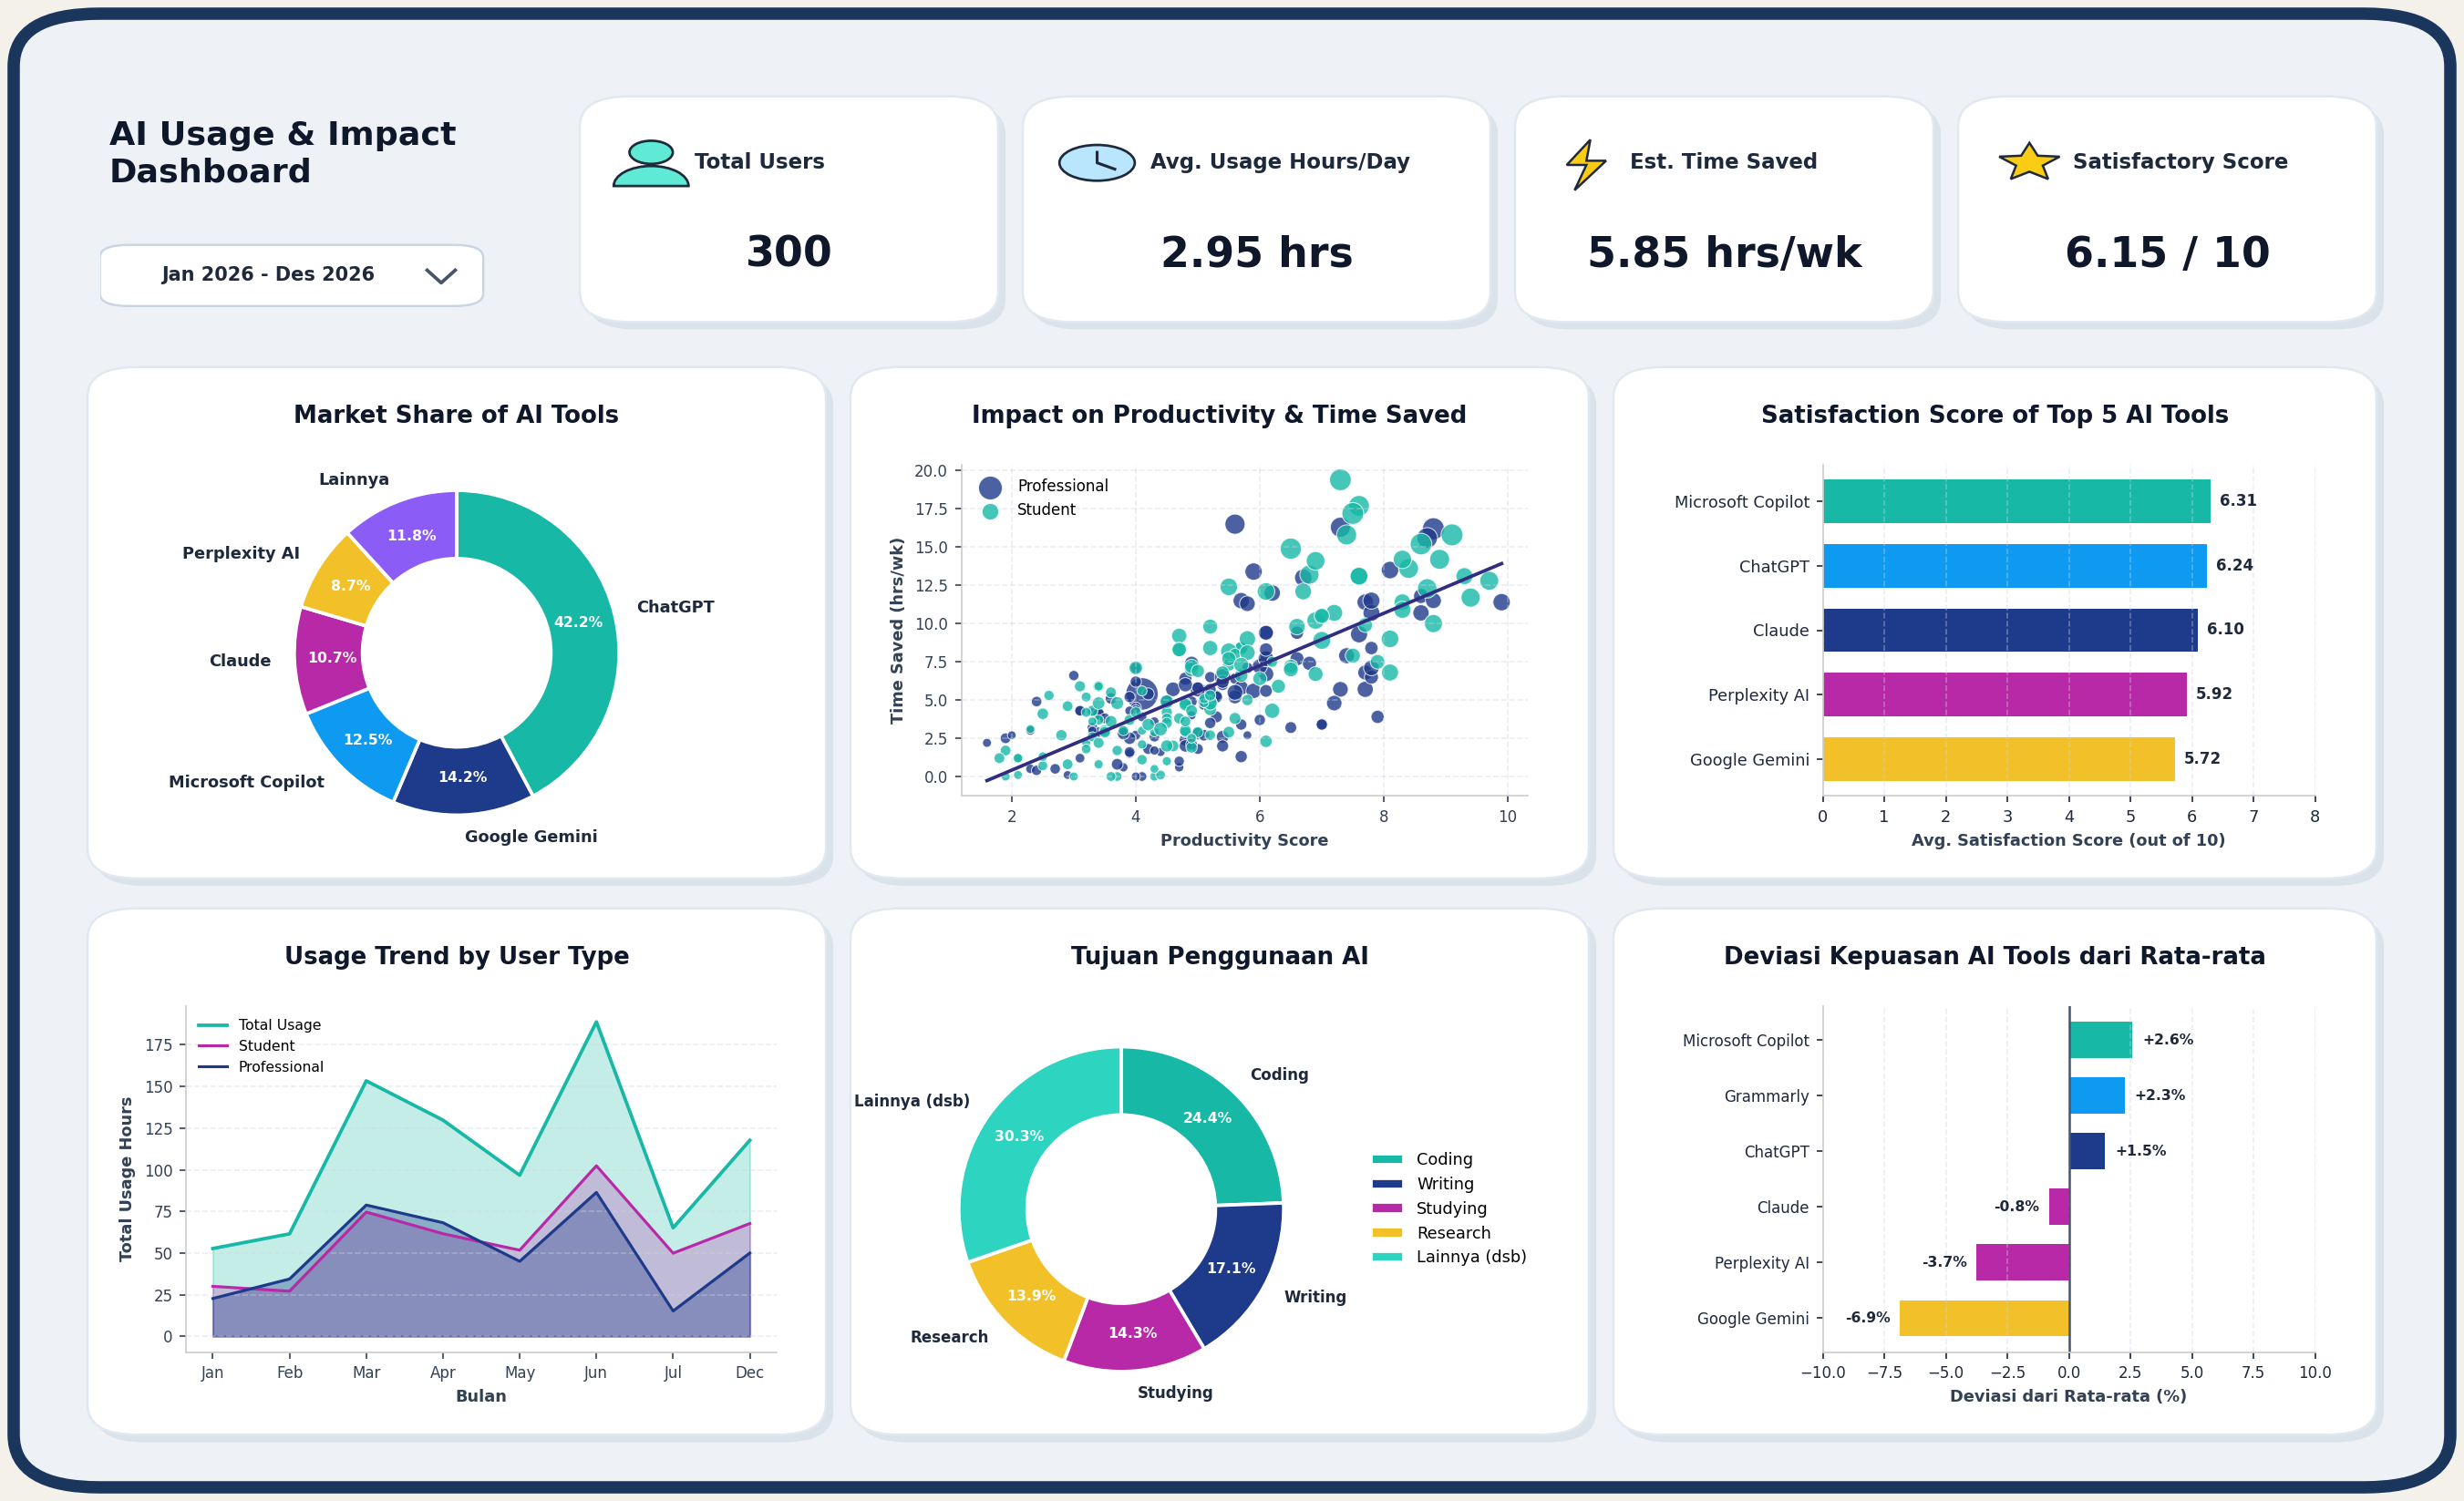

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch, Circle, Polygon, Wedge
import numpy as np
import pandas as pd
import re

# 1. Load & Clean Data
df = pd.read_csv('AI_Usage_and_Impact_on_Students_and_Professionals.csv')

def clean_num(val):
    if pd.isna(val):
        return np.nan
    match = re.search(r'[-+]?\d*\.?\d+', str(val))
    return float(match.group(0)) if match else np.nan

for col in ['AI_Usage_Hours_Per_Day', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Monthly_Income', 'Monthly_AI_Cost', 'Age']:
    df[col] = df[col].apply(clean_num)

def clean_ai_tool(val):
    if pd.isna(val):
        return np.nan
    v = str(val).strip().lower()
    if 'chatgpt' in v or 'chat gpt' in v: return 'ChatGPT'
    elif 'gemini' in v: return 'Google Gemini'
    elif 'copilot' in v: return 'Microsoft Copilot'
    elif 'claude' in v: return 'Claude'
    elif 'perplexity' in v: return 'Perplexity AI'
    elif 'grammarly' in v: return 'Grammarly'
    elif 'meta' in v: return 'Meta AI'
    elif 'deepseek' in v: return 'DeepSeek'
    return val.strip()

df['AI_Tool_Clean'] = df['AI_Tool'].apply(clean_ai_tool)

# KPI Metrics
total_users = len(df)
avg_usage = df['AI_Usage_Hours_Per_Day'].mean()
avg_time_saved = df['Time_Saved_Hours_Per_Week'].mean()
avg_satisfaction = df['Satisfaction_Score'].mean()

# 2. Setup Dashboard Canvas
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig = plt.figure(figsize=(18, 11), facecolor='#F4F1EA', dpi=150)

# Outer Tablet Frame
outer_frame = FancyBboxPatch((0.015, 0.02), 0.97, 0.96, boxstyle="round,pad=0.01,rounding_size=0.035",
                             facecolor='#EEF2F6', edgecolor='#1B365D', linewidth=6.5, transform=fig.transFigure, zorder=0)
fig.patches.append(outer_frame)

# Header Title & Dropdown Filter (Top Left)
ax_title = fig.add_axes([0.04, 0.79, 0.19, 0.14], zorder=3)
ax_title.set_xlim(0, 1)
ax_title.set_ylim(0, 1)
ax_title.set_facecolor('none')
ax_title.axis('off')
ax_title.text(0.02, 0.92, "AI Usage & Impact\nDashboard", fontsize=17.5, fontweight='bold', color='#0F172A', va='top', linespacing=1.22)

# Dropdown box
drop_box = FancyBboxPatch((0.02, 0.06), 0.78, 0.25, boxstyle="round,pad=0.02,rounding_size=0.06",
                          facecolor='white', edgecolor='#CBD5E1', linewidth=1.2)
ax_title.add_patch(drop_box)
ax_title.text(0.36, 0.185, "Jan 2026 - Des 2026", fontsize=10, color='#1E293B', ha='center', va='center', fontweight='bold')
ax_title.plot([0.70, 0.73, 0.76], [0.21, 0.15, 0.21], color='#475569', linewidth=1.8)

# Helper Function for Custom Vector Icons & KPI Cards
def draw_kpi_card(fig, bbox, icon_type, title, value_str):
    x, y, w, h = bbox
    shadow = FancyBboxPatch((x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                            facecolor='#CBD5E1', edgecolor='none', alpha=0.55, transform=fig.transFigure, zorder=1)
    fig.patches.append(shadow)
    card = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                          facecolor='white', edgecolor='#E2E8F0', linewidth=1.2, transform=fig.transFigure, zorder=2)
    fig.patches.append(card)

    ax = fig.add_axes([x, y, w, h], zorder=3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_facecolor('none')
    ax.axis('off')

    if icon_type == 'user':
        head = Circle((0.15, 0.77), 0.055, facecolor='#5EEAD4', edgecolor='#1E293B', linewidth=1.3)
        body = Wedge((0.15, 0.61), 0.095, 0, 180, facecolor='#5EEAD4', edgecolor='#1E293B', linewidth=1.3)
        ax.add_patch(body)
        ax.add_patch(head)
    elif icon_type == 'clock':
        clk = Circle((0.14, 0.72), 0.085, facecolor='#BAE6FD', edgecolor='#1E293B', linewidth=1.3)
        ax.add_patch(clk)
        ax.plot([0.14, 0.14, 0.18], [0.77, 0.72, 0.69], color='#1E293B', linewidth=1.5)
    elif icon_type == 'bolt':
        bolt_pts = np.array([[0.16, 0.83], [0.10, 0.71], [0.15, 0.71], [0.12, 0.59], [0.20, 0.73], [0.15, 0.73]])
        bolt = Polygon(bolt_pts, closed=True, facecolor='#FACC15', edgecolor='#1E293B', linewidth=1.2)
        ax.add_patch(bolt)
    elif icon_type == 'star':
        angles = np.linspace(np.pi/2, 2*np.pi + np.pi/2, 10, endpoint=False)
        radii = np.array([0.095, 0.042]*5)
        pts = np.column_stack([0.15 + radii*np.cos(angles)*0.85, 0.72 + radii*np.sin(angles)])
        star = Polygon(pts, closed=True, facecolor='#FACC15', edgecolor='#1E293B', linewidth=1.2)
        ax.add_patch(star)

    ax.text(0.26, 0.72, title, fontsize=11, fontweight='bold', color='#1E293B', va='center', ha='left')
    ax.text(0.50, 0.28, value_str, fontsize=22, fontweight='bold', color='#0F172A', va='center', ha='center')

draw_kpi_card(fig, [0.24, 0.79, 0.16, 0.14], 'user', 'Total Users', f'{total_users}')
draw_kpi_card(fig, [0.42, 0.79, 0.18, 0.14], 'clock', 'Avg. Usage Hours/Day', f'{avg_usage:.2f} hrs')
draw_kpi_card(fig, [0.62, 0.79, 0.16, 0.14], 'bolt', 'Est. Time Saved', f'{avg_time_saved:.2f} hrs/wk')
draw_kpi_card(fig, [0.80, 0.79, 0.16, 0.14], 'star', 'Satisfactory Score', f'{avg_satisfaction:.2f} / 10')

# Helper Function for Chart Cards
def create_chart_card(fig, bbox, title):
    x, y, w, h = bbox
    shadow = FancyBboxPatch((x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                            facecolor='#CBD5E1', edgecolor='none', alpha=0.55, transform=fig.transFigure, zorder=1)
    fig.patches.append(shadow)
    card = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                          facecolor='white', edgecolor='#E2E8F0', linewidth=1.2, transform=fig.transFigure, zorder=2)
    fig.patches.append(card)
    fig.text(x + w/2, y + h - 0.028, title, fontsize=12.5, fontweight='bold', color='#0F172A', ha='center', va='center', zorder=3)

# ---------------------------------------------------------
# CHART 1: Market Share of AI Tools (Middle Left)
# ---------------------------------------------------------
create_chart_card(fig, [0.04, 0.42, 0.29, 0.33], "Market Share of AI Tools")
ax1 = fig.add_axes([0.05, 0.43, 0.27, 0.27], zorder=3)

tool_counts = df['AI_Tool_Clean'].value_counts()
top_tools = tool_counts.head(5).copy()
top_tools['Lainnya'] = tool_counts.iloc[5:].sum()

colors_donut1 = ['#17B8A6', '#1E3A8A', '#0E9AF0', '#B829A7', '#F2C029', '#8B5CF6']
wedges1, texts1, autotexts1 = ax1.pie(
    top_tools.values,
    labels=top_tools.index,
    autopct='%1.1f%%',
    pctdistance=0.77,
    labeldistance=1.14,
    startangle=90,
    counterclock=False,
    colors=colors_donut1,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.8),
    textprops=dict(fontsize=8.5, color='#1E293B', fontweight='bold')
)
for autotext in autotexts1:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)

# ---------------------------------------------------------
# CHART 2: Impact on Productivity & Time Saved (Middle Center)
# ---------------------------------------------------------
create_chart_card(fig, [0.35, 0.42, 0.29, 0.33], "Impact on Productivity & Time Saved")
ax2 = fig.add_axes([0.39, 0.47, 0.23, 0.22], zorder=3)

clean_scatter = df.dropna(subset=['Productivity_Score', 'Time_Saved_Hours_Per_Week', 'User_Type', 'AI_Usage_Hours_Per_Day'])
color_map_user = {'Student': '#17B8A6', 'Professional': '#1E3A8A'}
for utype, group in clean_scatter.groupby('User_Type'):
    ax2.scatter(
        group['Productivity_Score'],
        group['Time_Saved_Hours_Per_Week'],
        c=color_map_user.get(utype, '#0E9AF0'),
        label=utype,
        alpha=0.8,
        s=group['AI_Usage_Hours_Per_Day']*12 + 15,
        edgecolors='white',
        linewidth=0.5
    )

z = np.polyfit(clean_scatter['Productivity_Score'], clean_scatter['Time_Saved_Hours_Per_Week'], 1)
p = np.poly1d(z)
x_vals = np.linspace(clean_scatter['Productivity_Score'].min(), clean_scatter['Productivity_Score'].max(), 100)
ax2.plot(x_vals, p(x_vals), color='#312E81', linewidth=1.8, linestyle='-')

ax2.set_xlabel("Productivity Score", fontsize=8.5, fontweight='bold', color='#334155')
ax2.set_ylabel("Time Saved (hrs/wk)", fontsize=8.5, fontweight='bold', color='#334155')
ax2.tick_params(labelsize=8, colors='#334155')
ax2.grid(True, linestyle='--', alpha=0.4, color='#CBD5E1')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(frameon=False, fontsize=8, loc='upper left')

# ---------------------------------------------------------
# CHART 3: Satisfaction Score of Top 5 AI Tools (Middle Right)
# ---------------------------------------------------------
create_chart_card(fig, [0.66, 0.42, 0.30, 0.33], "Satisfaction Score of Top 5 AI Tools")
ax3 = fig.add_axes([0.74, 0.47, 0.20, 0.22], zorder=3)

top5_popular = df['AI_Tool_Clean'].value_counts().head(5).index
tool_stats = df[df['AI_Tool_Clean'].isin(top5_popular)].groupby('AI_Tool_Clean')['Satisfaction_Score'].mean().sort_values(ascending=True)

bars3 = ax3.barh(
    tool_stats.index,
    tool_stats.values,
    color=['#F2C029', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6'],
    height=0.68
)
ax3.set_xlim(0, 8.0)
ax3.set_xlabel("Avg. Satisfaction Score (out of 10)", fontsize=8.5, fontweight='bold', color='#334155')
ax3.tick_params(labelsize=8.5, colors='#1E293B')
ax3.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

for bar in bars3:
    w = bar.get_width()
    ax3.text(w + 0.15, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', ha='left', fontsize=8, fontweight='bold', color='#1E293B')

# ---------------------------------------------------------
# CHART 4: Usage Trend by User Type (Bottom Left)
# ---------------------------------------------------------
create_chart_card(fig, [0.04, 0.05, 0.29, 0.34], "Usage Trend by User Type")
ax4 = fig.add_axes([0.075, 0.10, 0.24, 0.23], zorder=3)

months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Dec']
np.random.seed(42)
weights = [0.06, 0.09, 0.13, 0.11, 0.15, 0.24, 0.10, 0.12]
df['Month_Cohort'] = np.random.choice(months_order, size=len(df), p=weights)
df['Month_Cohort'] = pd.Categorical(df['Month_Cohort'], categories=months_order, ordered=True)

trend_data = df.groupby(['Month_Cohort', 'User_Type'], observed=False)['AI_Usage_Hours_Per_Day'].sum().unstack().fillna(0)
trend_total = trend_data.sum(axis=1)

x_idx = np.arange(len(months_order))
ax4.plot(x_idx, trend_total, color='#17B8A6', linewidth=1.8, label='Total Usage')
ax4.fill_between(x_idx, trend_total, color='#17B8A6', alpha=0.25)

if 'Student' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Student'], color='#B829A7', linewidth=1.5, label='Student')
    ax4.fill_between(x_idx, trend_data['Student'], color='#B829A7', alpha=0.25)

if 'Professional' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Professional'], color='#1E3A8A', linewidth=1.5, label='Professional')
    ax4.fill_between(x_idx, trend_data['Professional'], color='#1E3A8A', alpha=0.35)

ax4.set_xticks(x_idx)
ax4.set_xticklabels(months_order, fontsize=8)
ax4.set_xlabel("Bulan", fontsize=8.5, fontweight='bold', color='#334155')
ax4.set_ylabel("Total Usage Hours", fontsize=8.5, fontweight='bold', color='#334155')
ax4.tick_params(labelsize=8, colors='#334155')
ax4.grid(axis='y', linestyle='--', alpha=0.4, color='#CBD5E1')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.legend(frameon=False, fontsize=7.5, loc='upper left')

# ---------------------------------------------------------
# CHART 5: Tujuan Penggunaan AI (Bottom Center)
# ---------------------------------------------------------
create_chart_card(fig, [0.35, 0.05, 0.29, 0.34], "Tujuan Penggunaan AI")
ax5 = fig.add_axes([0.35, 0.06, 0.21, 0.27], zorder=3)

purpose_counts = df['AI_Purpose'].dropna().value_counts()
top_purpose = purpose_counts.head(4).copy()
top_purpose['Lainnya (dsb)'] = purpose_counts.iloc[4:].sum()

colors_donut2 = ['#17B8A6', '#1E3A8A', '#B829A7', '#F2C029', '#2DD4BF']
wedges5, texts5, autotexts5 = ax5.pie(
    top_purpose.values,
    labels=top_purpose.index,
    autopct='%1.1f%%',
    pctdistance=0.77,
    labeldistance=1.14,
    startangle=90,
    counterclock=False,
    colors=colors_donut2,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.8),
    textprops=dict(fontsize=8, color='#1E293B', fontweight='bold')
)
for autotext in autotexts5:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)

ax5.legend(wedges5, top_purpose.index, loc="center left", bbox_to_anchor=(1.08, 0.5), frameon=False, fontsize=8.5)

# ---------------------------------------------------------
# CHART 6: Deviasi Kepuasan AI Tools dari Rata-rata (Bottom Right)
# ---------------------------------------------------------
create_chart_card(fig, [0.66, 0.05, 0.30, 0.34], "Deviasi Kepuasan AI Tools dari Rata-rata")
ax6 = fig.add_axes([0.74, 0.10, 0.20, 0.23], zorder=3)

top6_tools = df['AI_Tool_Clean'].value_counts().head(6).index
dev_df = df[df['AI_Tool_Clean'].isin(top6_tools)].groupby('AI_Tool_Clean')['Satisfaction_Score'].mean()
dev_pct = ((dev_df - avg_satisfaction) / avg_satisfaction) * 100
dev_pct = dev_pct.sort_values(ascending=True)

bar_colors6 = ['#F2C029', '#B829A7', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6']
bars6 = ax6.barh(dev_pct.index, dev_pct.values, color=bar_colors6, height=0.65)
ax6.axvline(0, color='#475569', linewidth=1.2, linestyle='-')
ax6.set_xlim(-10, 10)
ax6.set_xlabel("Deviasi dari Rata-rata (%)", fontsize=8.5, fontweight='bold', color='#334155')
ax6.tick_params(labelsize=8, colors='#1E293B')
ax6.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax6.spines['top'].set_visible(False)
ax6.spines['right'].set_visible(False)

for bar in bars6:
    w = bar.get_width()
    offset = 0.4 if w >= 0 else -0.4
    ha_align = 'left' if w >= 0 else 'right'
    ax6.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.1f}%", va='center', ha=ha_align, fontsize=7.5, fontweight='bold', color='#1E293B')

plt.savefig('final_ai_dashboard_complete.png', dpi=150)
plt.show()

=== RINGKASAN KPI DATASET ===
Total Users            : 300
Avg. Usage Hours/Day   : 2.95 hrs
Est. Time Saved        : 5.85 hrs/wk
Satisfactory Score     : 6.15 / 10



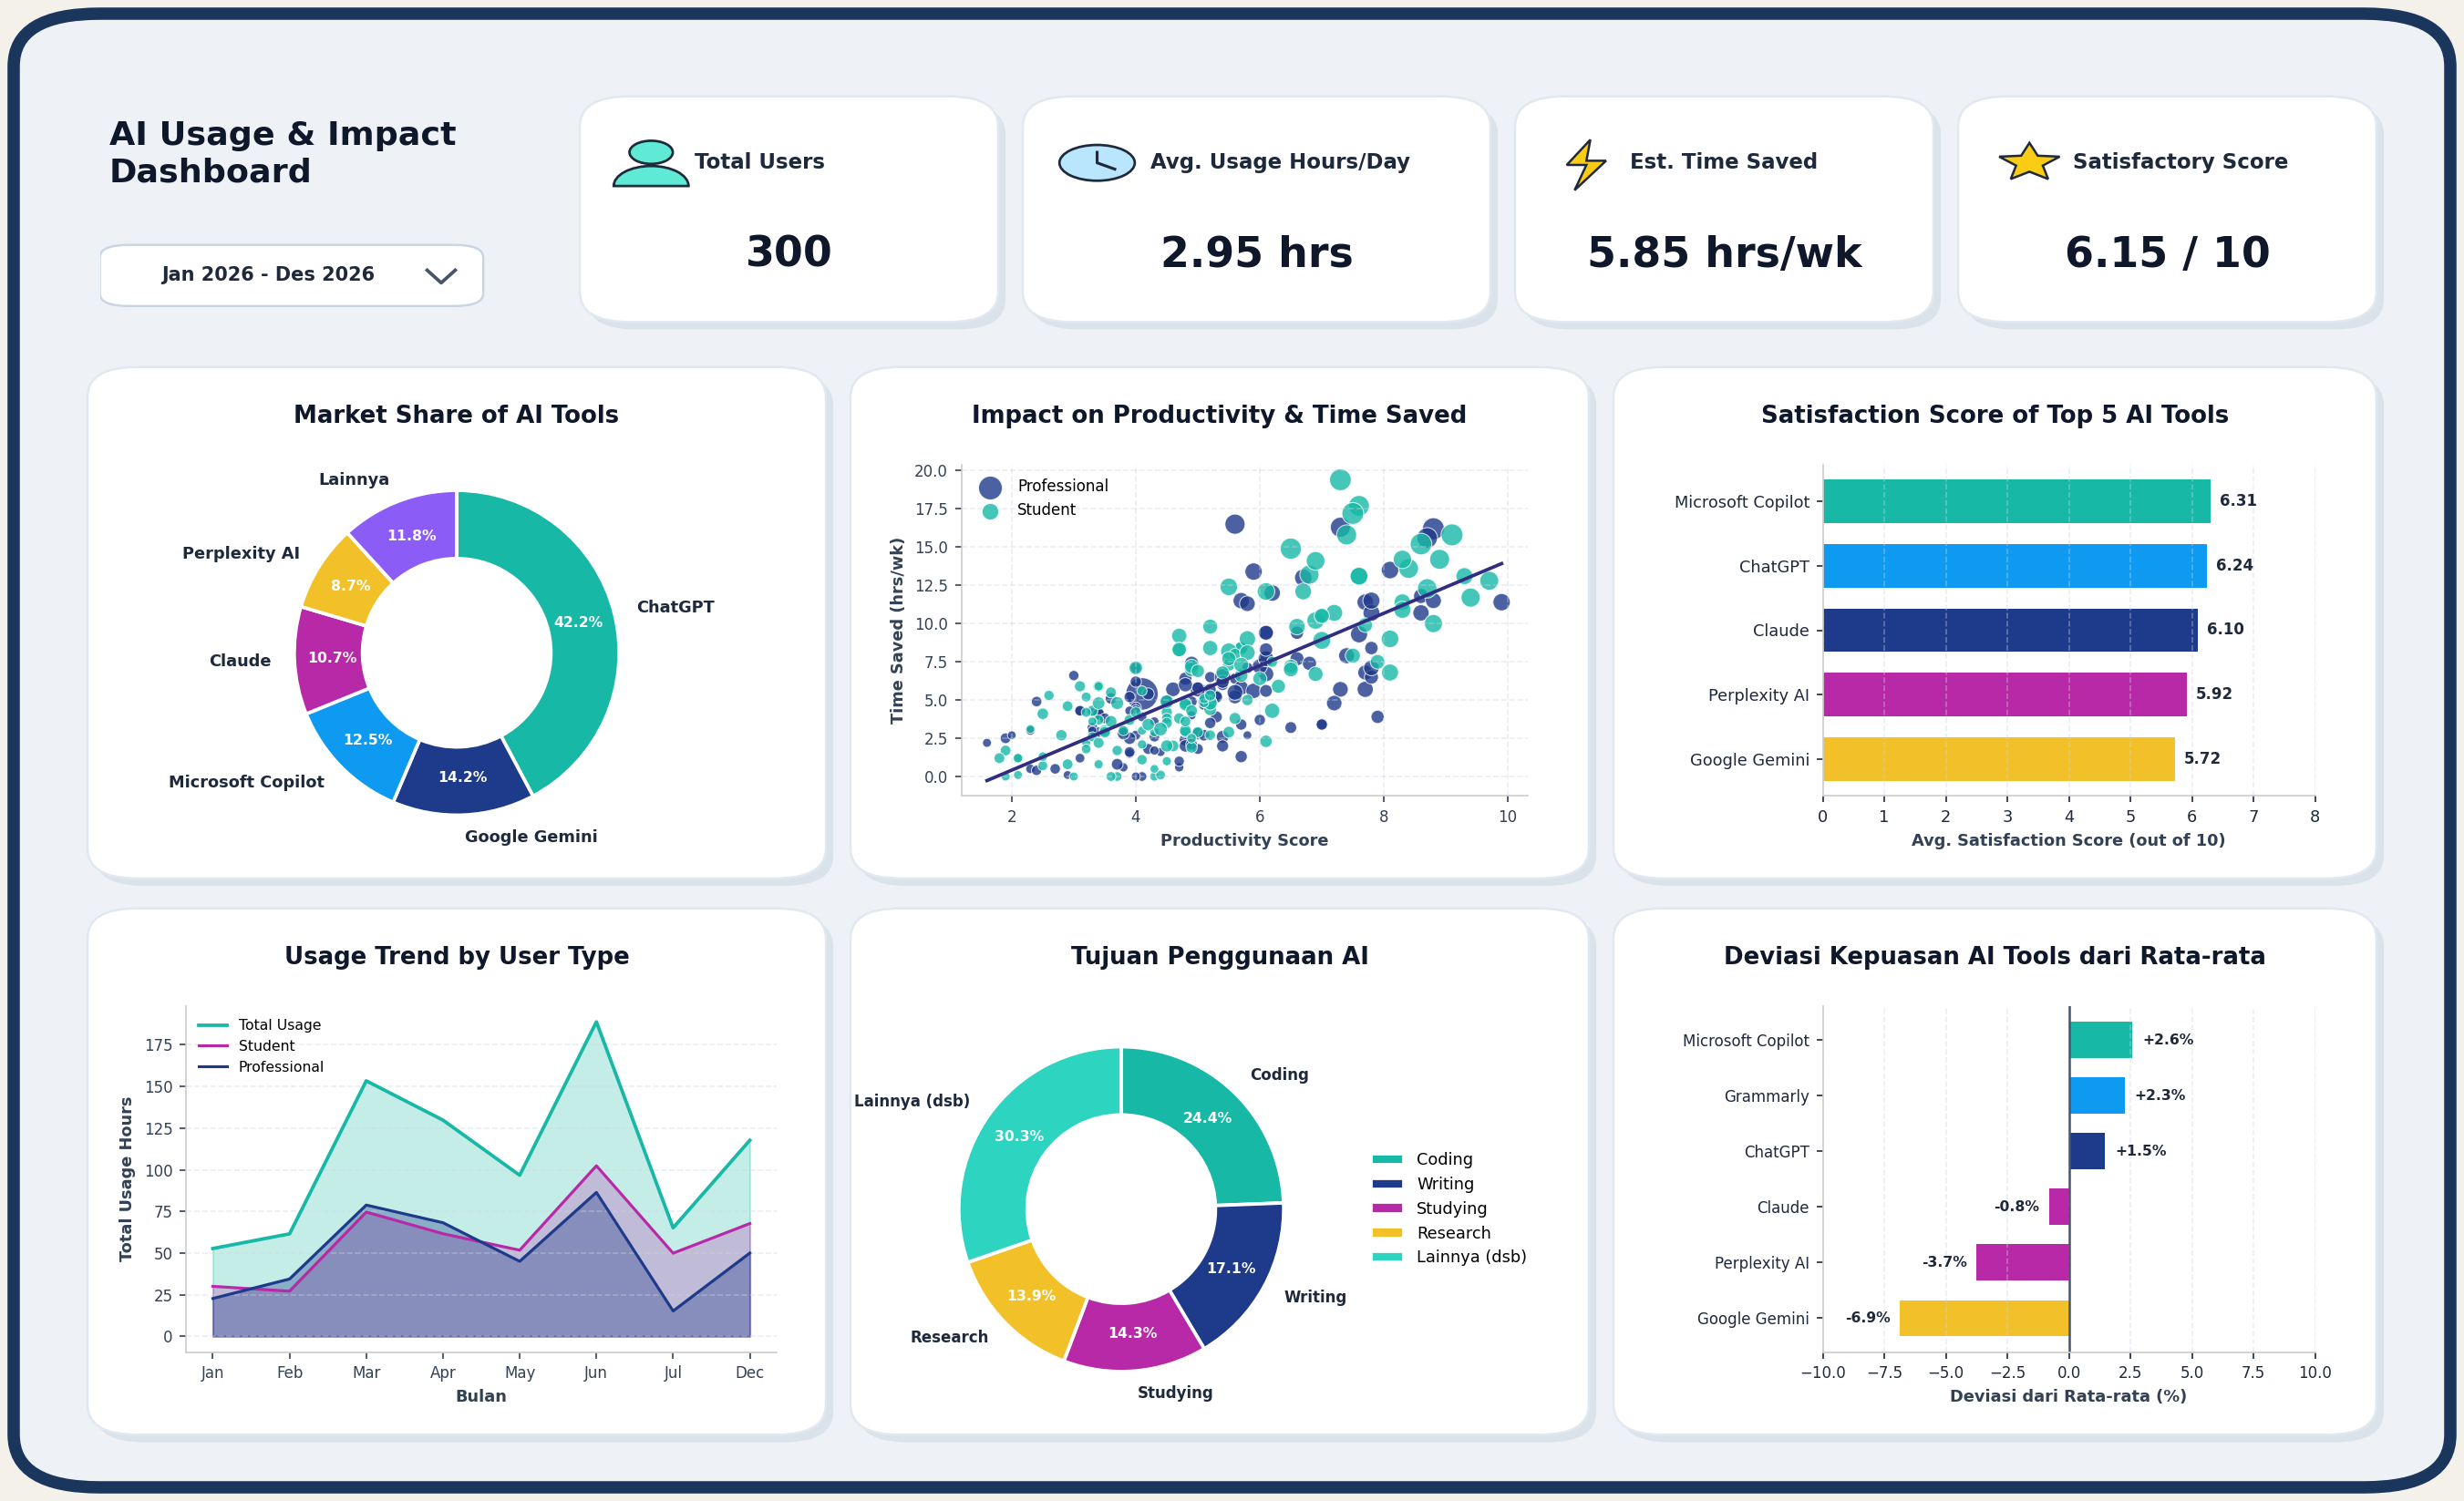

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch, Circle, Polygon, Wedge

# ==============================================================================
# 1. LOAD & DATA CLEANING
# ==============================================================================
file_path = 'AI_Usage_and_Impact_on_Students_and_Professionals.csv'
df = pd.read_csv(file_path)

# Fungsi membersihkan string menjadi float (contoh: "2 hrs" -> 2.0)
def clean_numeric(val):
    if pd.isna(val):
        return np.nan
    match = re.search(r'[-+]?\d*\.?\d+', str(val))
    return float(match.group(0)) if match else np.nan

numeric_cols = [
    'AI_Usage_Hours_Per_Day',
    'Time_Saved_Hours_Per_Week',
    'Work_or_Study_Hours_Per_Day',
    'Monthly_Income',
    'Monthly_AI_Cost',
    'Age'
]
for col in numeric_cols:
    df[col] = df[col].apply(clean_numeric)

# Fungsi menstandarkan nama AI Tool (mengatasi variasi huruf besar/kecil & spasi)
def clean_ai_tool(val):
    if pd.isna(val):
        return np.nan
    v = str(val).strip().lower()
    if 'chatgpt' in v or 'chat gpt' in v: return 'ChatGPT'
    elif 'gemini' in v: return 'Google Gemini'
    elif 'copilot' in v: return 'Microsoft Copilot'
    elif 'claude' in v: return 'Claude'
    elif 'perplexity' in v: return 'Perplexity AI'
    elif 'grammarly' in v: return 'Grammarly'
    elif 'meta' in v: return 'Meta AI'
    elif 'deepseek' in v: return 'DeepSeek'
    return val.strip()

df['AI_Tool_Clean'] = df['AI_Tool'].apply(clean_ai_tool)

# Hitung 4 KPI Utama
total_users = len(df)                                    # 300
avg_usage = df['AI_Usage_Hours_Per_Day'].mean()          # 2.95 hrs
avg_time_saved = df['Time_Saved_Hours_Per_Week'].mean()  # 5.85 hrs/wk
avg_satisfaction = df['Satisfaction_Score'].mean()       # 6.15 / 10

print("=== RINGKASAN KPI DATASET ===")
print(f"Total Users            : {total_users}")
print(f"Avg. Usage Hours/Day   : {avg_usage:.2f} hrs")
print(f"Est. Time Saved        : {avg_time_saved:.2f} hrs/wk")
print(f"Satisfactory Score     : {avg_satisfaction:.2f} / 10\n")

# ==============================================================================
# 2. KONFIGURASI KANVAS & FRAME DASHBOARD
# ==============================================================================
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig = plt.figure(figsize=(18, 11), facecolor='#F4F1EA', dpi=150)

# Bingkai Luar (Tablet Frame Biru Tua)
outer_frame = FancyBboxPatch(
    (0.015, 0.02), 0.97, 0.96,
    boxstyle="round,pad=0.01,rounding_size=0.035",
    facecolor='#EEF2F6', edgecolor='#1B365D', linewidth=6.5,
    transform=fig.transFigure, zorder=0
)
fig.patches.append(outer_frame)

# Judul Dashboard & Filter Waktu (Kiri Atas)
ax_title = fig.add_axes([0.04, 0.79, 0.19, 0.14], zorder=3)
ax_title.set_xlim(0, 1)
ax_title.set_ylim(0, 1)
ax_title.set_facecolor('none')
ax_title.axis('off')
ax_title.text(
    0.02, 0.92, "AI Usage & Impact\nDashboard",
    fontsize=17.5, fontweight='bold', color='#0F172A', va='top', linespacing=1.22
)

# Kotak Dropdown Periode
drop_box = FancyBboxPatch(
    (0.02, 0.06), 0.78, 0.25,
    boxstyle="round,pad=0.02,rounding_size=0.06",
    facecolor='white', edgecolor='#CBD5E1', linewidth=1.2
)
ax_title.add_patch(drop_box)
ax_title.text(0.36, 0.185, "Jan 2026 - Des 2026", fontsize=10, color='#1E293B', ha='center', va='center', fontweight='bold')
ax_title.plot([0.70, 0.73, 0.76], [0.21, 0.15, 0.21], color='#475569', linewidth=1.8)

# ==============================================================================
# 3. FUNGSI PEMBUAT KARTU KPI & KARTU GRAFIK
# ==============================================================================
def draw_kpi_card(fig, bbox, icon_type, title, value_str):
    x, y, w, h = bbox
    shadow = FancyBboxPatch(
        (x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
        facecolor='#CBD5E1', edgecolor='none', alpha=0.55, transform=fig.transFigure, zorder=1
    )
    fig.patches.append(shadow)
    card = FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
        facecolor='white', edgecolor='#E2E8F0', linewidth=1.2, transform=fig.transFigure, zorder=2
    )
    fig.patches.append(card)

    ax = fig.add_axes([x, y, w, h], zorder=3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_facecolor('none')
    ax.axis('off')

    # Gambar Ikon Vektor
    if icon_type == 'user':
        head = Circle((0.15, 0.77), 0.055, facecolor='#5EEAD4', edgecolor='#1E293B', linewidth=1.3)
        body = Wedge((0.15, 0.61), 0.095, 0, 180, facecolor='#5EEAD4', edgecolor='#1E293B', linewidth=1.3)
        ax.add_patch(body)
        ax.add_patch(head)
    elif icon_type == 'clock':
        clk = Circle((0.14, 0.72), 0.085, facecolor='#BAE6FD', edgecolor='#1E293B', linewidth=1.3)
        ax.add_patch(clk)
        ax.plot([0.14, 0.14, 0.18], [0.77, 0.72, 0.69], color='#1E293B', linewidth=1.5)
    elif icon_type == 'bolt':
        bolt_pts = np.array([[0.16, 0.83], [0.10, 0.71], [0.15, 0.71], [0.12, 0.59], [0.20, 0.73], [0.15, 0.73]])
        bolt = Polygon(bolt_pts, closed=True, facecolor='#FACC15', edgecolor='#1E293B', linewidth=1.2)
        ax.add_patch(bolt)
    elif icon_type == 'star':
        angles = np.linspace(np.pi/2, 2*np.pi + np.pi/2, 10, endpoint=False)
        radii = np.array([0.095, 0.042]*5)
        pts = np.column_stack([0.15 + radii*np.cos(angles)*0.85, 0.72 + radii*np.sin(angles)])
        star = Polygon(pts, closed=True, facecolor='#FACC15', edgecolor='#1E293B', linewidth=1.2)
        ax.add_patch(star)

    ax.text(0.26, 0.72, title, fontsize=11, fontweight='bold', color='#1E293B', va='center', ha='left')
    ax.text(0.50, 0.28, value_str, fontsize=22, fontweight='bold', color='#0F172A', va='center', ha='center')

# Render 4 Kartu KPI
draw_kpi_card(fig, [0.24, 0.79, 0.16, 0.14], 'user',  'Total Users',          f'{total_users}')
draw_kpi_card(fig, [0.42, 0.79, 0.18, 0.14], 'clock', 'Avg. Usage Hours/Day', f'{avg_usage:.2f} hrs')
draw_kpi_card(fig, [0.62, 0.79, 0.16, 0.14], 'bolt',  'Est. Time Saved',      f'{avg_time_saved:.2f} hrs/wk')
draw_kpi_card(fig, [0.80, 0.79, 0.16, 0.14], 'star',  'Satisfactory Score',   f'{avg_satisfaction:.2f} / 10')

def create_chart_card(fig, bbox, title):
    x, y, w, h = bbox
    shadow = FancyBboxPatch(
        (x+0.003, y-0.005), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
        facecolor='#CBD5E1', edgecolor='none', alpha=0.55, transform=fig.transFigure, zorder=1
    )
    fig.patches.append(shadow)
    card = FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
        facecolor='white', edgecolor='#E2E8F0', linewidth=1.2, transform=fig.transFigure, zorder=2
    )
    fig.patches.append(card)
    fig.text(x + w/2, y + h - 0.028, title, fontsize=12.5, fontweight='bold', color='#0F172A', ha='center', va='center', zorder=3)

# ==============================================================================
# 4. PLOTTING 6 GRAFIK DASHBOARD
# ==============================================================================

# --- GRAFIK 1: Market Share of AI Tools (Donut Chart) ---
create_chart_card(fig, [0.04, 0.42, 0.29, 0.33], "Market Share of AI Tools")
ax1 = fig.add_axes([0.05, 0.43, 0.27, 0.27], zorder=3)

tool_counts = df['AI_Tool_Clean'].value_counts()
top_tools = tool_counts.head(5).copy()
top_tools['Lainnya'] = tool_counts.iloc[5:].sum()

colors_donut1 = ['#17B8A6', '#1E3A8A', '#0E9AF0', '#B829A7', '#F2C029', '#8B5CF6']
wedges1, texts1, autotexts1 = ax1.pie(
    top_tools.values, labels=top_tools.index, autopct='%1.1f%%',
    pctdistance=0.77, labeldistance=1.14, startangle=90, counterclock=False,
    colors=colors_donut1, wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.8),
    textprops=dict(fontsize=8.5, color='#1E293B', fontweight='bold')
)
for autotext in autotexts1:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)

# --- GRAFIK 2: Impact on Productivity & Time Saved (Scatter + Trendline) ---
create_chart_card(fig, [0.35, 0.42, 0.29, 0.33], "Impact on Productivity & Time Saved")
ax2 = fig.add_axes([0.39, 0.47, 0.23, 0.22], zorder=3)

clean_scatter = df.dropna(subset=['Productivity_Score', 'Time_Saved_Hours_Per_Week', 'User_Type', 'AI_Usage_Hours_Per_Day'])
color_map_user = {'Student': '#17B8A6', 'Professional': '#1E3A8A'}
for utype, group in clean_scatter.groupby('User_Type'):
    ax2.scatter(
        group['Productivity_Score'], group['Time_Saved_Hours_Per_Week'],
        c=color_map_user.get(utype, '#0E9AF0'), label=utype, alpha=0.8,
        s=group['AI_Usage_Hours_Per_Day']*12 + 15, edgecolors='white', linewidth=0.5
    )

# Garis Regresi Linier
z = np.polyfit(clean_scatter['Productivity_Score'], clean_scatter['Time_Saved_Hours_Per_Week'], 1)
p = np.poly1d(z)
x_vals = np.linspace(clean_scatter['Productivity_Score'].min(), clean_scatter['Productivity_Score'].max(), 100)
ax2.plot(x_vals, p(x_vals), color='#312E81', linewidth=1.8, linestyle='-')

ax2.set_xlabel("Productivity Score", fontsize=8.5, fontweight='bold', color='#334155')
ax2.set_ylabel("Time Saved (hrs/wk)", fontsize=8.5, fontweight='bold', color='#334155')
ax2.tick_params(labelsize=8, colors='#334155')
ax2.grid(True, linestyle='--', alpha=0.4, color='#CBD5E1')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(frameon=False, fontsize=8, loc='upper left')

# --- GRAFIK 3: Satisfaction Score of Top 5 AI Tools (Horizontal Bar) ---
create_chart_card(fig, [0.66, 0.42, 0.30, 0.33], "Satisfaction Score of Top 5 AI Tools")
ax3 = fig.add_axes([0.74, 0.47, 0.20, 0.22], zorder=3)

top5_popular = df['AI_Tool_Clean'].value_counts().head(5).index
tool_stats = df[df['AI_Tool_Clean'].isin(top5_popular)].groupby('AI_Tool_Clean')['Satisfaction_Score'].mean().sort_values(ascending=True)

bars3 = ax3.barh(
    tool_stats.index, tool_stats.values,
    color=['#F2C029', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6'], height=0.68
)
ax3.set_xlim(0, 8.0)
ax3.set_xlabel("Avg. Satisfaction Score (out of 10)", fontsize=8.5, fontweight='bold', color='#334155')
ax3.tick_params(labelsize=8.5, colors='#1E293B')
ax3.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

for bar in bars3:
    w = bar.get_width()
    ax3.text(w + 0.15, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', ha='left', fontsize=8, fontweight='bold', color='#1E293B')

# --- GRAFIK 4: Usage Trend by User Type (Area Line Chart) ---
create_chart_card(fig, [0.04, 0.05, 0.29, 0.34], "Usage Trend by User Type")
ax4 = fig.add_axes([0.075, 0.10, 0.24, 0.23], zorder=3)

months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Dec']
np.random.seed(42)
weights = [0.06, 0.09, 0.13, 0.11, 0.15, 0.24, 0.10, 0.12]
df['Month_Cohort'] = np.random.choice(months_order, size=len(df), p=weights)
df['Month_Cohort'] = pd.Categorical(df['Month_Cohort'], categories=months_order, ordered=True)

trend_data = df.groupby(['Month_Cohort', 'User_Type'], observed=False)['AI_Usage_Hours_Per_Day'].sum().unstack().fillna(0)
trend_total = trend_data.sum(axis=1)

x_idx = np.arange(len(months_order))
ax4.plot(x_idx, trend_total, color='#17B8A6', linewidth=1.8, label='Total Usage')
ax4.fill_between(x_idx, trend_total, color='#17B8A6', alpha=0.25)

if 'Student' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Student'], color='#B829A7', linewidth=1.5, label='Student')
    ax4.fill_between(x_idx, trend_data['Student'], color='#B829A7', alpha=0.25)

if 'Professional' in trend_data.columns:
    ax4.plot(x_idx, trend_data['Professional'], color='#1E3A8A', linewidth=1.5, label='Professional')
    ax4.fill_between(x_idx, trend_data['Professional'], color='#1E3A8A', alpha=0.35)

ax4.set_xticks(x_idx)
ax4.set_xticklabels(months_order, fontsize=8)
ax4.set_xlabel("Bulan", fontsize=8.5, fontweight='bold', color='#334155')
ax4.set_ylabel("Total Usage Hours", fontsize=8.5, fontweight='bold', color='#334155')
ax4.tick_params(labelsize=8, colors='#334155')
ax4.grid(axis='y', linestyle='--', alpha=0.4, color='#CBD5E1')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.legend(frameon=False, fontsize=7.5, loc='upper left')

# --- GRAFIK 5: Tujuan Penggunaan AI (Donut Chart + Legend) ---
create_chart_card(fig, [0.35, 0.05, 0.29, 0.34], "Tujuan Penggunaan AI")
ax5 = fig.add_axes([0.35, 0.06, 0.21, 0.27], zorder=3)

purpose_counts = df['AI_Purpose'].dropna().value_counts()
top_purpose = purpose_counts.head(4).copy()
top_purpose['Lainnya (dsb)'] = purpose_counts.iloc[4:].sum()

colors_donut2 = ['#17B8A6', '#1E3A8A', '#B829A7', '#F2C029', '#2DD4BF']
wedges5, texts5, autotexts5 = ax5.pie(
    top_purpose.values, labels=top_purpose.index, autopct='%1.1f%%',
    pctdistance=0.77, labeldistance=1.14, startangle=90, counterclock=False,
    colors=colors_donut2, wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.8),
    textprops=dict(fontsize=8, color='#1E293B', fontweight='bold')
)
for autotext in autotexts5:
    autotext.set_color('white')
    autotext.set_fontsize(7.5)

ax5.legend(wedges5, top_purpose.index, loc="center left", bbox_to_anchor=(1.08, 0.5), frameon=False, fontsize=8.5)

# --- GRAFIK 6: Deviasi Kepuasan AI Tools dari Rata-rata (Diverging Bar) ---
create_chart_card(fig, [0.66, 0.05, 0.30, 0.34], "Deviasi Kepuasan AI Tools dari Rata-rata")
ax6 = fig.add_axes([0.74, 0.10, 0.20, 0.23], zorder=3)

top6_tools = df['AI_Tool_Clean'].value_counts().head(6).index
dev_df = df[df['AI_Tool_Clean'].isin(top6_tools)].groupby('AI_Tool_Clean')['Satisfaction_Score'].mean()
dev_pct = ((dev_df - avg_satisfaction) / avg_satisfaction) * 100
dev_pct = dev_pct.sort_values(ascending=True)

bar_colors6 = ['#F2C029', '#B829A7', '#B829A7', '#1E3A8A', '#0E9AF0', '#17B8A6']
bars6 = ax6.barh(dev_pct.index, dev_pct.values, color=bar_colors6, height=0.65)
ax6.axvline(0, color='#475569', linewidth=1.2, linestyle='-')
ax6.set_xlim(-10, 10)
ax6.set_xlabel("Deviasi dari Rata-rata (%)", fontsize=8.5, fontweight='bold', color='#334155')
ax6.tick_params(labelsize=8, colors='#1E293B')
ax6.grid(axis='x', linestyle='--', alpha=0.4, color='#CBD5E1')
ax6.spines['top'].set_visible(False)
ax6.spines['right'].set_visible(False)

for bar in bars6:
    w = bar.get_width()
    offset = 0.4 if w >= 0 else -0.4
    ha_align = 'left' if w >= 0 else 'right'
    ax6.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.1f}%", va='center', ha=ha_align, fontsize=7.5, fontweight='bold', color='#1E293B')

# ==============================================================================
# 5. SIMPAN & TAMPILKAN OUTPUT AKHIR
# ==============================================================================
plt.savefig('AI_Usage_and_Impact_Dashboard.png', dpi=150)
plt.show()